In [1]:

"""
============================================================================
WINDOW 1: DATA LOADING, PREPROCESSING, AND CONFIGURATION
============================================================================
Complete implementation comparing:
1. Pure Neural Network
2. Physics-Informed Neural Network (PINN)
3. Hybrid AI-Physics Model
4. OGS Reference Data
============================================================================
"""

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import time
from io import StringIO
from scipy.special import erfc
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

print("="*80)
print("RESEARCH STUDY: PURE NN vs PINN vs HYBRID AI-PHYSICS vs OGS")
print("="*80)

# ============================================================================
# CONFIGURATION
# ============================================================================

class Config:
    """Configuration parameters for all models"""
    
    # Neural network architecture
    input_dim = 2  # (x, t)
    hidden_layers = [128, 128, 128, 128, 128]
    output_dim = 3  # (P, T, u)
    
    # Training parameters
    epochs = 5000
    batch_size = 32
    learning_rate = 0.001
    train_split = 0.7
    
    # Device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    
    # Regularization
    dropout_rate = 0.05
    weight_decay = 1e-6
    
    # Learning rate scheduler
    use_scheduler = True
    scheduler_patience = 300
    scheduler_factor = 0.5
    
    # Physics-informed loss weights (PINN)
    lambda_data = 1.0
    lambda_ic = 1.0
    lambda_bc = 1.0
    lambda_pde = 0.01
    
    # Hybrid model weights
    lambda_physics = 0.6  # Weight for physics-based prediction
    lambda_correction = 0.4  # Weight for NN correction
    
    # Physical parameters (AnSichT test case)
    P_initial = 4.0e6  # Pa
    T_initial = 25.0   # °C
    u_initial = 0.0    # m
    
    P_boundary = 4.0e6  # Pa
    T_boundary = 25.0   # °C
    u_boundary = 0.0    # m
    
    # Domain
    x_borehole = 0.25   # m
    x_farfield = 10.0   # m
    
    # THM physical parameters
    k_permeability = 1e-20  # m²
    mu_viscosity = 1e-3     # Pa·s
    phi_porosity = 0.4      # -
    alpha_thermal = 1e-6    # m²/s (thermal diffusivity)
    alpha_expansion = 1e-5  # 1/K (thermal expansion)
    
    # Borehole conditions
    P_borehole = 6.0e6   # Pa
    T_borehole = 100.0   # °C

print(f"\nConfiguration:")
print(f"  Device: {Config.device}")
print(f"  Architecture: {Config.input_dim} → {Config.hidden_layers} → {Config.output_dim}")
print(f"  Training: {Config.epochs} epochs, batch size {Config.batch_size}")

# ============================================================================
# DATA LOADING
# ============================================================================

uploaded_files = {
    "1.pressure with OGS at x=5m.csv": """Time t/days,Pressure P/Pa
0,3995366.795
14.74103586,3989189.189
33.01992032,3995366.795
44.812749,3983011.583
51.5936255,3970656.371
62.20717131,4081853.282
72.2310757,4217760.618
81.96015936,4415444.015
93.75298805,4674903.475
102.5976096,4823166.023
110.8525896,4965250.965
124.7091633,5175289.575
135.6175299,5280308.88
145.0517928,5385328.185
154.7808765,5453281.853
165.0996016,5515057.915
185.4422311,5607722.008
204.6055777,5681853.282
245.5856574,5762162.162
265.9282869,5762162.162
285.3864542,5737451.737
304.8446215,5718918.919
325.4820717,5700386.1
344.3505976,5681853.282
364.9880478,5644787.645""",
    
    "1.temperature with OGS at x=5m.csv": """Time t/days,Temperature T/?
2.039898494,24.63411049
15.775363,24.86568853
26.00593118,24.37802583
40.91080431,24.48859057
54.35326925,24.9608654
67.21343455,24.71199974
77.14915342,25.06630085
85.04016446,25.06117156
94.3898842,25.89686623
100.8192269,26.01294021
108.1260886,25.88793746
116.891659,26.60375868
125.659079,26.71831287
135.8866876,27.19267741
146.1150361,27.42653514
156.0492752,28.26184986
166.5709932,28.1347574
186.1486915,29.32456321
206.8994979,29.19082167
226.4786759,29.89961385
245.4729647,30.72903939
265.9289218,31.43726166
286.0948389,31.42415347
305.9666466,32.01250227
324.9627851,32.24066079
344.543443,32.46843936
365.2912898,33.29672505""",
    
    "1.x-displacement with OGS at x=5m.csv": """Time t/days,x-axis displacement xl/m
0,2.04E-06
2.040441176,-2.32E-05
11.5625,-2.95E-05
25.16544118,-3.45E-05
30.60661765,-3.96E-05
37.06801471,7.23E-06
43.86948529,6.79E-05
50.67095588,0.00013117
64.95404412,0.000238678
75.49632353,0.000314567
87.05882353,0.000384139
104.0625,0.000446144
124.4669118,0.000501839
155.0735294,0.000546192
184.3198529,0.000565255
225.1286765,0.000583093
265.5974265,0.000590817
305.3860294,0.000594746
324.7702206,0.000593548
345.1746324,0.000592353
364.8988971,0.000598742""",
    
    "2.pressure with OGS at x=2.5m.csv": """Time t/days,Pressure P/Pa
0,3989189.189
9.729083665,3983011.583
20.6374502,3908880.309
33.31474104,3822393.822
38.32669323,3995366.795
41.2749004,4217760.618
44.812749,4538996.139
46.28685259,4724324.324
48.35059761,4946718.147
50.70916335,5175289.575
53.95219124,5490347.49
57.19521912,5749806.95
63.38645418,6064864.865
67.80876494,6250193.05
75.17928287,6460231.66
83.13944223,6583783.784
91.68924303,6657915.058
97.88047809,6657915.058
109.0836653,6639382.239
114.9800797,6620849.421
125.2988048,6589961.39
144.4621514,6472586.873
165.0996016,6318146.718
204.9003984,6120463.32
244.7011952,5904247.104
284.7968127,5700386.1
305.4342629,5601544.402
325.4820717,5508880.309
344.940239,5440926.641
364.9880478,5360617.761""",
    
    "2.temperature with OGS at x=2.5m.csv": """Time t/days,Temperature T/?
5.253644997,24.992781
18.98947945,25.10410563
32.14116452,25.09555681
43.8289616,25.9297317
53.1746119,28.08821383
65.14874947,30.84625322
74.49476972,32.88448194
80.92115288,33.96258316
87.63942576,35.16074782
93.48202948,35.99872218
100.492932,37.07644345
108.9655028,38.03296145
115.1007361,38.75049243
125.6183847,39.94618743
135.5526237,40.78150215
145.7776427,42.09764053
156.0052513,42.57200506
166.2324899,43.16662301
185.5182985,44.23636538
205.0956268,45.54642459
225.2596942,46.13458343
245.4226517,47.08350248
265.0010898,48.03280147
284.8728975,48.62115028
305.3288546,49.32937255
324.9098824,49.43689771
344.4898004,49.90518308
365.2394969,50.13220176""",
    
    "2.x-displacement with OGS at x=2.5m.csv": """Time t/days,x-axis displacement xl/m
0,0
1.700367647,-7.13E-05
10.20220588,-9.27E-05
24.48529412,-0.000115443
29.92647059,-0.000119217
32.64705882,-5.47E-05
36.04779412,6.79E-05
42.50919118,0.000206995
46.59007353,0.000289184
52.37132353,0.000376435
63.59375,0.000451062
78.55698529,0.00051306
94.20036765,0.000552305
114.9448529,0.000580188
134.3290441,0.00058784
155.0735294,0.000592968
185.3400735,0.000598128
224.4485294,0.000598262
264.2371324,0.000599662
286.3419118,0.000599737
304.3658088,0.000596006
325.7904412,0.000597344
344.8345588,0.000593616
364.21875,0.000597475""",
    
    "3.pressure with OGS at x=1m.csv": """Time t/days,Pressure P/Pa
0,4001544.402
2.358565737,3865637.066
3.832669323,3661776.062
5.601593625,3427027.027
8.25498008,3260231.66
12.0876494,3074903.475
20.04780876,2846332.046
26.23904382,2741312.741
31.25099602,2691891.892
32.43027888,2852509.653
32.43027888,3031660.232
32.43027888,3229343.629
33.31474104,3389961.39
33.60956175,3637065.637
33.31474104,3995366.795
33.60956175,4242471.042
33.60956175,4526640.927
35.37848606,4897297.297
35.37848606,5138223.938
35.67330677,5360617.761
36.26294821,5545945.946
37.44223108,5768339.768
38.03187251,5904247.104
38.62151394,6163706.564
40.98007968,6349034.749
43.0438247,6571428.571
47.46613546,6682625.483
52.47808765,6608494.208
58.07968127,6447876.448
66.33466135,6200772.201
79.30677291,5904247.104
87.26693227,5700386.1
100.2390438,5447104.247
114.9800797,5175289.575
132.6693227,4903474.903
150.3585657,4742857.143
164.2151394,4557528.958
184.8525896,4409266.409
205.1952191,4248648.649
225.8326693,4112741.313
244.7011952,3989189.189
264.749004,3877992.278
285.3864542,3816216.216
306.3187251,3729729.73
323.4183267,3674131.274
345.5298805,3575289.575
364.3984064,3544401.544""",
    
    "3.temperature with OGS at x=1m.csv": """Time t/days,Temperature T/?
2.331048315,24.99468073
11.6833577,24.98860157
23.37374442,24.98100262
32.14153447,24.97530341
33.59173434,28.58195569
37.67227123,32.18689821
40.58006995,36.99513467
43.78086824,41.56267435
49.02600441,46.60989783
56.60440859,53.21889579
67.69214848,59.10409364
76.15769024,62.34542633
87.54434888,66.06587291
104.1924214,69.54239315
125.5177585,72.65511359
135.7420376,74.21175878
155.6101458,76.00264164
165.8359046,77.0782732
185.1206034,78.50877579
205.5758205,79.45750486
225.4465184,80.40661389
245.6091059,81.47578634
265.1875441,82.42508534
286.2276506,83.25318106
305.2230492,83.72184639
325.6793762,84.30981525
344.6744049,84.89873397
365.1325817,84.88543581""",
    
    "3.x-displacement with OGS at x=1m.csv": """Time t/days,x-axis displacement xl/m
0,-4.84E-07
0.340073529,-0.000115526
0.680147059,-0.000171155
2.380514706,-0.000211599
10.88235294,-0.000241912
23.125,-0.000248191
29.58639706,-0.000253226
31.28676471,-0.000201387
32.64705882,-0.000119208
34.34742647,-2.44E-05
37.40808824,7.30E-05
48.97058824,0.000170355
68.35477941,0.000218462
91.13970588,0.000245088
115.625,0.000257814
136.3694853,0.000260413
153.3731618,0.000266793
185.3400735,0.000268166
224.4485294,0.000270828
265.2573529,0.000273496
325.1102941,0.000280022
345.1746324,0.000276297
365.2389706,0.000281423""",
    
    "4.pressure with OGS at x=0.5m.csv": """Time t/days,Pressure P/Pa
0,3989189.189
0.589641434,3445559.846
0.294820717,3241698.842
1.474103586,2691891.892
3.832669323,2395366.795
4.422310757,2197683.398
5.601593625,1938223.938
10.61354582,1715830.116
16.80478088,1592277.992
25.05976096,1468725.869
29.48207171,1437837.838
31.25099602,1783783.784
31.54581673,2210038.61
31.25099602,2951351.351
32.43027888,3513513.514
33.90438247,4131274.131
33.60956175,4477220.077
36.55776892,4650193.05
45.69721116,4261003.861
54.24701195,3945945.946
63.38645418,3630888.031
72.82071713,3383783.784
90.21513944,3087258.687
106.4302789,2908108.108
126.7729084,2673359.073
154.4860558,2457142.857
184.8525896,2296525.097
225.2430279,2148262.548
264.749004,2037065.637
304.8446215,1956756.757
344.940239,1870270.27
364.9880478,1845559.846""",
    
    "4.temperature with OGS at x=0.5m.csv": """Time t/days,Temperature T/?
2.623307983,24.99449076
13.14465604,24.9876517
24.25052343,24.9804327
30.68023613,24.97625328
31.24662797,30.86829018
32.68646927,37.8420378
33.25286111,43.7340747
35.28055128,49.62516173
36.72668172,54.55460146
38.76066103,58.40138061
42.53709988,65.85462206
47.77261738,74.02843408
54.76354263,81.59983922
66.14095255,88.32662093
78.98521004,93.24865169
88.03749083,95.768084
99.13595924,98.1659331
114.616103,101.282453
136.8193289,104.0338433
165.159638,106.9014976
205.775223,109.6409196
245.8073986,112.0199612
265.3876865,112.3679932
305.1298221,114.0257045
346.0443259,114.6003751
364.7452452,115.7907509""",
    
    "4.x-displacement with OGS at x=0.5m.csv": """Time t/days,x-axis displacement xl/m
0,2.04E-06
0.340073529,-4.60E-05
3.400735294,-0.000405022
15.30330882,-0.000410038
23.125,-0.000406219
29.24632353,-0.000406198
30.60661765,-0.000355624
32.30698529,-0.000293672
36.72794118,-0.000227917
46.25,-0.000205128
58.83272059,-0.000182329
77.87683824,-0.000174679
95.56066176,-0.000168298
114.2647059,-0.000169498
154.3933824,-0.000165568
204.3841912,-0.000164133
245.1930147,-0.000166522
285.6617647,-0.000162591
325.1102941,-0.000163721
364.21875,-0.000166115"""
}

def load_reference_data():
    """Load all reference data from uploaded files"""
    data_dict = {}
    position_map = {'1': 5.0, '2': 2.5, '3': 1.0, '4': 0.5}
    
    for filename, content in uploaded_files.items():
        file_id = filename.split('.')[0]
        x_pos = position_map[file_id]
        
        if 'pressure' in filename:
            var_type = 'pressure'
        elif 'temperature' in filename:
            var_type = 'temperature'
        elif 'displacement' in filename:
            var_type = 'displacement'
        
        df = pd.read_csv(StringIO(content))
        key = (x_pos, var_type)
        data_dict[key] = df
    
    return data_dict

def prepare_training_data(data_dict):
    """Prepare training dataset from reference data"""
    X_list = []
    y_list = []
    x_positions = sorted(list(set([key[0] for key in data_dict.keys()])))
    
    for x_pos in x_positions:
        pressure_df = data_dict.get((x_pos, 'pressure'))
        temperature_df = data_dict.get((x_pos, 'temperature'))
        displacement_df = data_dict.get((x_pos, 'displacement'))
        
        time_points = set()
        if pressure_df is not None:
            time_points.update(pressure_df.iloc[:, 0].values)
        if temperature_df is not None:
            time_points.update(temperature_df.iloc[:, 0].values)
        if displacement_df is not None:
            time_points.update(displacement_df.iloc[:, 0].values)
        
        time_points = sorted(list(time_points))
        
        for t in time_points:
            if pressure_df is not None:
                P = np.interp(t, pressure_df.iloc[:, 0].values, pressure_df.iloc[:, 1].values)
            else:
                continue
            
            if temperature_df is not None:
                T = np.interp(t, temperature_df.iloc[:, 0].values, temperature_df.iloc[:, 1].values)
            else:
                continue
            
            if displacement_df is not None:
                u = np.interp(t, displacement_df.iloc[:, 0].values, displacement_df.iloc[:, 1].values)
            else:
                continue
            
            X_list.append([x_pos, t])
            y_list.append([P, T, u])
    
    X = np.array(X_list)
    y = np.array(y_list)
    
    return X, y

print("\n" + "="*80)
print("STEP 1: DATA LOADING AND PREPROCESSING")
print("="*80)

data_dict = load_reference_data()
X, y = prepare_training_data(data_dict)

print(f"\nOGS Reference Data Loaded:")
print(f"  Total data points: {len(X)}")
print(f"  Spatial positions: {sorted(list(set(X[:, 0])))} m")
print(f"  Time range: [{X[:, 1].min():.1f}, {X[:, 1].max():.1f}] days")
print(f"\n  Data Ranges:")
print(f"    x: [{X[:, 0].min():.2f}, {X[:, 0].max():.2f}] m")
print(f"    t: [{X[:, 1].min():.2f}, {X[:, 1].max():.2f}] days")
print(f"    P: [{y[:, 0].min():.2e}, {y[:, 0].max():.2e}] Pa")
print(f"    T: [{y[:, 1].min():.2f}, {y[:, 1].max():.2f}] °C")
print(f"    u: [{y[:, 2].min():.2e}, {y[:, 2].max():.2e}] m")

# Normalize data
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_normalized = scaler_X.fit_transform(X)
y_normalized = scaler_y.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_normalized, y_normalized, test_size=0.3, random_state=42
)

print(f"\nData Split:")
print(f"  Training samples: {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)")
print(f"  Test samples: {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)")

# Create PyTorch datasets
class THMDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.FloatTensor(y)
    
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = THMDataset(X_train, y_train)
test_dataset = THMDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=Config.batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=Config.batch_size, shuffle=False)

print(f"\nPyTorch DataLoaders Created:")
print(f"  Batch size: {Config.batch_size}")
print(f"  Training batches: {len(train_loader)}")
print(f"  Test batches: {len(test_loader)}")

print("\n" + "="*80)
print("WINDOW 1 COMPLETED: Data loaded and preprocessed successfully!")
print("="*80)



RESEARCH STUDY: PURE NN vs PINN vs HYBRID AI-PHYSICS vs OGS

Configuration:
  Device: cpu
  Architecture: 2 → [128, 128, 128, 128, 128] → 3
  Training: 5000 epochs, batch size 32

STEP 1: DATA LOADING AND PREPROCESSING

OGS Reference Data Loaded:
  Total data points: 320
  Spatial positions: [0.5, 1.0, 2.5, 5.0] m
  Time range: [0.0, 365.3] days

  Data Ranges:
    x: [0.50, 5.00] m
    t: [0.00, 365.29] days
    P: [1.44e+06, 6.68e+06] Pa
    T: [24.38, 115.79] °C
    u: [-4.10e-04, 6.00e-04] m

Data Split:
  Training samples: 224 (70.0%)
  Test samples: 96 (30.0%)

PyTorch DataLoaders Created:
  Batch size: 32
  Training batches: 7
  Test batches: 3

WINDOW 1 COMPLETED: Data loaded and preprocessed successfully!


In [2]:
"""
============================================================================
WINDOW 2: NEURAL NETWORK ARCHITECTURES
============================================================================
Implementations of:
1. Pure Neural Network (Baseline)
2. Physics-Informed Neural Network (PINN)
3. Hybrid AI-Physics Model
============================================================================
"""

# ============================================================================
# 1. PURE NEURAL NETWORK (BASELINE)
# ============================================================================

class PureNN(nn.Module):
    """Pure data-driven neural network without physics constraints"""
    
    def __init__(self, input_dim, hidden_layers, output_dim, dropout_rate=0.05):
        super(PureNN, self).__init__()
        
        layers = []
        prev_dim = input_dim
        
        for hidden_dim in hidden_layers:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.LayerNorm(hidden_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_rate))
            prev_dim = hidden_dim
        
        layers.append(nn.Linear(prev_dim, output_dim))
        
        self.network = nn.Sequential(*layers)
        
        # Initialize weights
        self._initialize_weights()
    
    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
    
    def forward(self, x):
        return self.network(x)

# ============================================================================
# 2. PHYSICS-INFORMED NEURAL NETWORK (PINN)
# ============================================================================

class PINN(nn.Module):
    """Physics-Informed Neural Network with PDE constraints"""
    
    def __init__(self, input_dim, hidden_layers, output_dim, dropout_rate=0.05):
        super(PINN, self).__init__()
        
        layers = []
        prev_dim = input_dim
        
        for hidden_dim in hidden_layers:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.LayerNorm(hidden_dim))
            layers.append(nn.Tanh())  # Tanh for better gradient flow in PINN
            layers.append(nn.Dropout(dropout_rate))
            prev_dim = hidden_dim
        
        layers.append(nn.Linear(prev_dim, output_dim))
        
        self.network = nn.Sequential(*layers)
        
        # Physical parameters
        self.k = Config.k_permeability
        self.mu = Config.mu_viscosity
        self.phi = Config.phi_porosity
        self.alpha_thermal = Config.alpha_thermal
        self.alpha_expansion = Config.alpha_expansion
        
        self._initialize_weights()
    
    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
    
    def forward(self, x):
        return self.network(x)
    
    def compute_pde_residuals(self, x):
        """Compute PDE residuals for physics-informed loss"""
        x = x.requires_grad_(True)
        
        # Forward pass
        outputs = self.forward(x)
        P = outputs[:, 0:1]
        T = outputs[:, 1:2]
        u = outputs[:, 2:3]
        
        # Compute gradients
        # First derivatives
        P_x = torch.autograd.grad(P, x, torch.ones_like(P), create_graph=True)[0][:, 0:1]
        P_t = torch.autograd.grad(P, x, torch.ones_like(P), create_graph=True)[0][:, 1:2]
        
        T_x = torch.autograd.grad(T, x, torch.ones_like(T), create_graph=True)[0][:, 0:1]
        T_t = torch.autograd.grad(T, x, torch.ones_like(T), create_graph=True)[0][:, 1:2]
        
        u_x = torch.autograd.grad(u, x, torch.ones_like(u), create_graph=True)[0][:, 0:1]
        
        # Second derivatives
        P_xx = torch.autograd.grad(P_x, x, torch.ones_like(P_x), create_graph=True)[0][:, 0:1]
        T_xx = torch.autograd.grad(T_x, x, torch.ones_like(T_x), create_graph=True)[0][:, 0:1]
        
        # PDE residuals (simplified THM equations)
        # Hydraulic: ∂P/∂t = (k/μφ) ∂²P/∂x²
        hydraulic_diffusivity = self.k / (self.mu * self.phi)
        residual_H = P_t - hydraulic_diffusivity * P_xx
        
        # Thermal: ∂T/∂t = α ∂²T/∂x²
        residual_T = T_t - self.alpha_thermal * T_xx
        
        # Mechanical: ∂u/∂x = α_expansion * ΔT + (1/E) * ΔP (simplified)
        # For simplicity, we use a coupling term
        E_modulus = 1e9  # Young's modulus (Pa)
        residual_M = u_x - (self.alpha_expansion * T + P / E_modulus)
        
        return residual_H, residual_T, residual_M

# ============================================================================
# 3. HYBRID AI-PHYSICS MODEL
# ============================================================================

class PhysicsModel:
    """Analytical/semi-analytical physics-based model"""
    
    def __init__(self):
        self.k = Config.k_permeability
        self.mu = Config.mu_viscosity
        self.phi = Config.phi_porosity
        self.alpha_thermal = Config.alpha_thermal
        self.P_initial = Config.P_initial
        self.T_initial = Config.T_initial
        self.P_borehole = Config.P_borehole
        self.T_borehole = Config.T_borehole
        self.x_borehole = Config.x_borehole
    
    def predict(self, X):
        """
        Analytical solution using diffusion equations
        X: (N, 2) array with columns [x, t]
        Returns: (N, 3) array with columns [P, T, u]
        """
        x = X[:, 0]
        t = X[:, 1]
        
        # Convert time from days to seconds
        t_seconds = t * 86400
        
        # Pressure: radial diffusion from borehole
        hydraulic_diffusivity = self.k / (self.mu * self.phi)
        
        # Avoid division by zero
        t_seconds = np.maximum(t_seconds, 1e-6)
        x_safe = np.maximum(x, self.x_borehole)
        
        # Simplified radial diffusion solution
        eta_P = (x_safe - self.x_borehole) / (2 * np.sqrt(hydraulic_diffusivity * t_seconds))
        P = self.P_initial + (self.P_borehole - self.P_initial) * erfc(eta_P)
        
        # Temperature: thermal diffusion
        eta_T = (x_safe - self.x_borehole) / (2 * np.sqrt(self.alpha_thermal * t_seconds))
        T = self.T_initial + (self.T_borehole - self.T_initial) * erfc(eta_T)
        
        # Displacement: simplified thermal expansion + pressure effect
        alpha_expansion = Config.alpha_expansion
        E_modulus = 1e9  # Pa
        u = alpha_expansion * (T - self.T_initial) * x_safe + (P - self.P_initial) / E_modulus * x_safe * 1e-6
        
        return np.column_stack([P, T, u])

class HybridModel(nn.Module):
    """Hybrid model combining physics-based predictions with NN corrections"""
    
    def __init__(self, input_dim, hidden_layers, output_dim, dropout_rate=0.05):
        super(HybridModel, self).__init__()
        
        # Neural network for learning corrections/residuals
        layers = []
        prev_dim = input_dim + output_dim  # Input: (x, t) + physics predictions
        
        for hidden_dim in hidden_layers:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.LayerNorm(hidden_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_rate))
            prev_dim = hidden_dim
        
        layers.append(nn.Linear(prev_dim, output_dim))
        
        self.correction_network = nn.Sequential(*layers)
        
        # Physics model
        self.physics_model = PhysicsModel()
        
        # Weights for combining physics and correction
        self.lambda_physics = Config.lambda_physics
        self.lambda_correction = Config.lambda_correction
        
        self._initialize_weights()
    
    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
    
    def forward(self, x, scaler_X=None, scaler_y=None):
        """
        Forward pass combining physics and NN correction
        x: normalized input (x, t)
        """
        # Denormalize input for physics model
        if scaler_X is not None:
            x_denorm = scaler_X.inverse_transform(x.cpu().detach().numpy())
        else:
            x_denorm = x.cpu().detach().numpy()
        
        # Get physics-based prediction
        physics_pred = self.physics_model.predict(x_denorm)
        
        # Normalize physics prediction
        if scaler_y is not None:
            physics_pred_norm = scaler_y.transform(physics_pred)
        else:
            physics_pred_norm = physics_pred
        
        physics_pred_tensor = torch.FloatTensor(physics_pred_norm).to(x.device)
        
        # Concatenate input with physics prediction
        combined_input = torch.cat([x, physics_pred_tensor], dim=1)
        
        # Get NN correction
        correction = self.correction_network(combined_input)
        
        # Combine physics and correction
        output = self.lambda_physics * physics_pred_tensor + self.lambda_correction * correction
        
        return output
    
    def get_physics_prediction(self, x, scaler_X=None, scaler_y=None):
        """Get only the physics-based prediction"""
        if scaler_X is not None:
            x_denorm = scaler_X.inverse_transform(x.cpu().detach().numpy())
        else:
            x_denorm = x.cpu().detach().numpy()
        
        physics_pred = self.physics_model.predict(x_denorm)
        
        if scaler_y is not None:
            physics_pred_norm = scaler_y.transform(physics_pred)
        else:
            physics_pred_norm = physics_pred
        
        return torch.FloatTensor(physics_pred_norm).to(x.device)

print("\n" + "="*80)
print("WINDOW 2 COMPLETED: Neural network architectures defined!")
print("="*80)
print("\nModel Architectures:")
print(f"  1. Pure NN: Standard feedforward network")
print(f"  2. PINN: Physics-informed with PDE residuals")
print(f"  3. Hybrid: Physics model + NN correction")
print(f"     - Physics weight: {Config.lambda_physics}")
print(f"     - Correction weight: {Config.lambda_correction}")



WINDOW 2 COMPLETED: Neural network architectures defined!

Model Architectures:
  1. Pure NN: Standard feedforward network
  2. PINN: Physics-informed with PDE residuals
  3. Hybrid: Physics model + NN correction
     - Physics weight: 0.6
     - Correction weight: 0.4


In [3]:
"""
============================================================================
WINDOW 3: TRAINING FUNCTIONS AND LOSS COMPUTATIONS
============================================================================
Training procedures for all three models with appropriate loss functions
============================================================================
"""

# ============================================================================
# LOSS FUNCTIONS
# ============================================================================

def pure_nn_loss(predictions, targets):
    """Standard MSE loss for pure neural network"""
    return nn.MSELoss()(predictions, targets)

def pinn_loss(model, x, y, lambda_data=1.0, lambda_pde=0.01):
    """
    PINN loss = Data loss + PDE residual loss
    """
    # Data loss
    predictions = model(x)
    loss_data = nn.MSELoss()(predictions, y)
    
    # PDE residual loss
    residual_H, residual_T, residual_M = model.compute_pde_residuals(x)
    loss_pde = torch.mean(residual_H**2) + torch.mean(residual_T**2) + torch.mean(residual_M**2)
    
    # Combined loss
    total_loss = lambda_data * loss_data + lambda_pde * loss_pde
    
    return total_loss, loss_data, loss_pde

def hybrid_loss(predictions, targets):
    """Loss for hybrid model (standard MSE on combined output)"""
    return nn.MSELoss()(predictions, targets)

# ============================================================================
# TRAINING FUNCTIONS
# ============================================================================

def train_pure_nn(model, train_loader, test_loader, epochs, learning_rate, device):
    """Train pure neural network"""
    print("\n" + "="*80)
    print("TRAINING PURE NEURAL NETWORK")
    print("="*80)
    
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=Config.weight_decay)
    
    if Config.use_scheduler:
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode='min', factor=Config.scheduler_factor, 
            patience=Config.scheduler_patience, verbose=True
        )
    
    train_losses = []
    test_losses = []
    best_test_loss = float('inf')
    best_model_state = None
    
    start_time = time.time()
    
    for epoch in range(epochs):
        # Training
        model.train()
        train_loss = 0.0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            
            optimizer.zero_grad()
            predictions = model(batch_x)
            loss = pure_nn_loss(predictions, batch_y)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
        
        train_loss /= len(train_loader)
        train_losses.append(train_loss)
        
        # Testing
        model.eval()
        test_loss = 0.0
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                predictions = model(batch_x)
                loss = pure_nn_loss(predictions, batch_y)
                test_loss += loss.item()
        
        test_loss /= len(test_loader)
        test_losses.append(test_loss)
        
        # Learning rate scheduling
        if Config.use_scheduler:
            scheduler.step(test_loss)
        
        # Save best model
        if test_loss < best_test_loss:
            best_test_loss = test_loss
            best_model_state = model.state_dict().copy()
        
        # Print progress
        if (epoch + 1) % 500 == 0 or epoch == 0:
            elapsed = time.time() - start_time
            print(f"Epoch [{epoch+1}/{epochs}] | "
                  f"Train Loss: {train_loss:.6f} | "
                  f"Test Loss: {test_loss:.6f} | "
                  f"Time: {elapsed:.1f}s")
    
    # Load best model
    model.load_state_dict(best_model_state)
    
    training_time = time.time() - start_time
    print(f"\nTraining completed in {training_time:.2f} seconds")
    print(f"Best test loss: {best_test_loss:.6f}")
    
    return model, train_losses, test_losses, training_time

def train_pinn(model, train_loader, test_loader, epochs, learning_rate, device):
    """Train Physics-Informed Neural Network"""
    print("\n" + "="*80)
    print("TRAINING PHYSICS-INFORMED NEURAL NETWORK (PINN)")
    print("="*80)
    
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=Config.weight_decay)
    
    if Config.use_scheduler:
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode='min', factor=Config.scheduler_factor, 
            patience=Config.scheduler_patience, verbose=True
        )
    
    train_losses = []
    test_losses = []
    data_losses = []
    pde_losses = []
    best_test_loss = float('inf')
    best_model_state = None
    
    start_time = time.time()
    
    for epoch in range(epochs):
        # Training
        model.train()
        train_loss = 0.0
        epoch_data_loss = 0.0
        epoch_pde_loss = 0.0
        
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            
            optimizer.zero_grad()
            total_loss, loss_data, loss_pde = pinn_loss(
                model, batch_x, batch_y, 
                lambda_data=Config.lambda_data, 
                lambda_pde=Config.lambda_pde
            )
            total_loss.backward()
            optimizer.step()
            
            train_loss += total_loss.item()
            epoch_data_loss += loss_data.item()
            epoch_pde_loss += loss_pde.item()
        
        train_loss /= len(train_loader)
        epoch_data_loss /= len(train_loader)
        epoch_pde_loss /= len(train_loader)
        
        train_losses.append(train_loss)
        data_losses.append(epoch_data_loss)
        pde_losses.append(epoch_pde_loss)
        
        # Testing
        model.eval()
        test_loss = 0.0
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                predictions = model(batch_x)
                loss = pure_nn_loss(predictions, batch_y)
                test_loss += loss.item()
        
        test_loss /= len(test_loader)
        test_losses.append(test_loss)
        
        # Learning rate scheduling
        if Config.use_scheduler:
            scheduler.step(test_loss)
        
        # Save best model
        if test_loss < best_test_loss:
            best_test_loss = test_loss
            best_model_state = model.state_dict().copy()
        
        # Print progress
        if (epoch + 1) % 500 == 0 or epoch == 0:
            elapsed = time.time() - start_time
            print(f"Epoch [{epoch+1}/{epochs}] | "
                  f"Train Loss: {train_loss:.6f} | "
                  f"Test Loss: {test_loss:.6f} | "
                  f"Data: {epoch_data_loss:.6f} | "
                  f"PDE: {epoch_pde_loss:.6f} | "
                  f"Time: {elapsed:.1f}s")
    
    # Load best model
    model.load_state_dict(best_model_state)
    
    training_time = time.time() - start_time
    print(f"\nTraining completed in {training_time:.2f} seconds")
    print(f"Best test loss: {best_test_loss:.6f}")
    
    return model, train_losses, test_losses, training_time

def train_hybrid(model, train_loader, test_loader, epochs, learning_rate, device, scaler_X, scaler_y):
    """Train Hybrid AI-Physics Model"""
    print("\n" + "="*80)
    print("TRAINING HYBRID AI-PHYSICS MODEL")
    print("="*80)
    
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=Config.weight_decay)
    
    if Config.use_scheduler:
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode='min', factor=Config.scheduler_factor, 
            patience=Config.scheduler_patience, verbose=True
        )
    
    train_losses = []
    test_losses = []
    best_test_loss = float('inf')
    best_model_state = None
    
    start_time = time.time()
    
    for epoch in range(epochs):
        # Training
        model.train()
        train_loss = 0.0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            
            optimizer.zero_grad()
            predictions = model(batch_x, scaler_X, scaler_y)
            loss = hybrid_loss(predictions, batch_y)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
        
        train_loss /= len(train_loader)
        train_losses.append(train_loss)
        
        # Testing
        model.eval()
        test_loss = 0.0
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                predictions = model(batch_x, scaler_X, scaler_y)
                loss = hybrid_loss(predictions, batch_y)
                test_loss += loss.item()
        
        test_loss /= len(test_loader)
        test_losses.append(test_loss)
        
        # Learning rate scheduling
        if Config.use_scheduler:
            scheduler.step(test_loss)
        
        # Save best model
        if test_loss < best_test_loss:
            best_test_loss = test_loss
            best_model_state = model.state_dict().copy()
        
        # Print progress
        if (epoch + 1) % 500 == 0 or epoch == 0:
            elapsed = time.time() - start_time
            print(f"Epoch [{epoch+1}/{epochs}] | "
                  f"Train Loss: {train_loss:.6f} | "
                  f"Test Loss: {test_loss:.6f} | "
                  f"Time: {elapsed:.1f}s")
    
    # Load best model
    model.load_state_dict(best_model_state)
    
    training_time = time.time() - start_time
    print(f"\nTraining completed in {training_time:.2f} seconds")
    print(f"Best test loss: {best_test_loss:.6f}")
    
    return model, train_losses, test_losses, training_time

print("\n" + "="*80)
print("WINDOW 3 COMPLETED: Training functions defined!")
print("="*80)



WINDOW 3 COMPLETED: Training functions defined!


In [4]:
"""
============================================================================
WINDOW 4: MODEL TRAINING AND EVALUATION
============================================================================
Train all models and compute performance metrics
============================================================================
"""

# ============================================================================
# TRAIN ALL MODELS
# ============================================================================

print("\n" + "="*80)
print("STEP 2: TRAINING ALL MODELS")
print("="*80)

# Initialize models
pure_nn_model = PureNN(
    Config.input_dim, 
    Config.hidden_layers, 
    Config.output_dim, 
    Config.dropout_rate
)

pinn_model = PINN(
    Config.input_dim, 
    Config.hidden_layers, 
    Config.output_dim, 
    Config.dropout_rate
)

hybrid_model = HybridModel(
    Config.input_dim, 
    Config.hidden_layers, 
    Config.output_dim, 
    Config.dropout_rate
)

print(f"\nModel Parameters:")
print(f"  Pure NN: {sum(p.numel() for p in pure_nn_model.parameters()):,}")
print(f"  PINN: {sum(p.numel() for p in pinn_model.parameters()):,}")
print(f"  Hybrid: {sum(p.numel() for p in hybrid_model.parameters()):,}")

# Train Pure NN
pure_nn_trained, pure_nn_train_losses, pure_nn_test_losses, pure_nn_time = train_pure_nn(
    pure_nn_model, train_loader, test_loader, 
    Config.epochs, Config.learning_rate, Config.device
)

# Train PINN
pinn_trained, pinn_train_losses, pinn_test_losses, pinn_time = train_pinn(
    pinn_model, train_loader, test_loader, 
    Config.epochs, Config.learning_rate, Config.device
)

# Train Hybrid
hybrid_trained, hybrid_train_losses, hybrid_test_losses, hybrid_time = train_hybrid(
    hybrid_model, train_loader, test_loader, 
    Config.epochs, Config.learning_rate, Config.device,
    scaler_X, scaler_y
)

print("\n" + "="*80)
print("TRAINING SUMMARY")
print("="*80)
print(f"\nTraining Times:")
print(f"  Pure NN: {pure_nn_time:.2f} seconds")
print(f"  PINN: {pinn_time:.2f} seconds")
print(f"  Hybrid: {hybrid_time:.2f} seconds")

# ============================================================================
# EVALUATION FUNCTIONS
# ============================================================================

def evaluate_model(model, X_test, y_test, scaler_X, scaler_y, model_type='pure_nn'):
    """Evaluate model and compute metrics"""
    model.eval()
    
    X_test_tensor = torch.FloatTensor(X_test).to(Config.device)
    
    with torch.no_grad():
        if model_type == 'hybrid':
            y_pred_norm = model(X_test_tensor, scaler_X, scaler_y).cpu().numpy()
        else:
            y_pred_norm = model(X_test_tensor).cpu().numpy()
    
    # Denormalize predictions
    y_pred = scaler_y.inverse_transform(y_pred_norm)
    y_true = scaler_y.inverse_transform(y_test)
    
    # Compute metrics for each output
    metrics = {}
    output_names = ['Pressure', 'Temperature', 'Displacement']
    
    for i, name in enumerate(output_names):
        y_true_i = y_true[:, i]
        y_pred_i = y_pred[:, i]
        
        r2 = r2_score(y_true_i, y_pred_i)
        mae = mean_absolute_error(y_true_i, y_pred_i)
        rmse = np.sqrt(mean_squared_error(y_true_i, y_pred_i))
        mape = np.mean(np.abs((y_true_i - y_pred_i) / (np.abs(y_true_i) + 1e-10))) * 100
        
        metrics[name] = {
            'R2': r2,
            'MAE': mae,
            'RMSE': rmse,
            'MAPE': mape
        }
    
    return metrics, y_pred, y_true

# ============================================================================
# EVALUATE ALL MODELS
# ============================================================================

print("\n" + "="*80)
print("STEP 3: MODEL EVALUATION")
print("="*80)

# Evaluate Pure NN
pure_nn_metrics, pure_nn_pred, y_true = evaluate_model(
    pure_nn_trained, X_test, y_test, scaler_X, scaler_y, 'pure_nn'
)

# Evaluate PINN
pinn_metrics, pinn_pred, _ = evaluate_model(
    pinn_trained, X_test, y_test, scaler_X, scaler_y, 'pinn'
)

# Evaluate Hybrid
hybrid_metrics, hybrid_pred, _ = evaluate_model(
    hybrid_trained, X_test, y_test, scaler_X, scaler_y, 'hybrid'
)

# Get physics-only predictions for comparison
physics_model = PhysicsModel()
X_test_denorm = scaler_X.inverse_transform(X_test)
physics_pred = physics_model.predict(X_test_denorm)

# Compute physics model metrics
physics_metrics = {}
output_names = ['Pressure', 'Temperature', 'Displacement']
for i, name in enumerate(output_names):
    y_true_i = y_true[:, i]
    y_pred_i = physics_pred[:, i]
    
    r2 = r2_score(y_true_i, y_pred_i)
    mae = mean_absolute_error(y_true_i, y_pred_i)
    rmse = np.sqrt(mean_squared_error(y_true_i, y_pred_i))
    mape = np.mean(np.abs((y_true_i - y_pred_i) / (np.abs(y_true_i) + 1e-10))) * 100
    
    physics_metrics[name] = {
        'R2': r2,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    }

# ============================================================================
# PRINT RESULTS
# ============================================================================

def print_metrics_table(metrics_dict):
    """Print metrics in a formatted table"""
    models = ['Physics-Only', 'Pure NN', 'PINN', 'Hybrid']
    metrics_list = [physics_metrics, pure_nn_metrics, pinn_metrics, hybrid_metrics]
    
    for output_name in ['Pressure', 'Temperature', 'Displacement']:
        print(f"\n{output_name}:")
        print("-" * 95)
        print(f"{'Model':<15} {'R²':<12} {'MAE':<20} {'RMSE':<20} {'MAPE (%)':<12}")
        print("-" * 95)
        
        for model_name, metrics in zip(models, metrics_list):
            m = metrics[output_name]
            
            # Format values based on output type
            if output_name == 'Pressure':
                mae_str = f"{m['MAE']:.2e} Pa"
                rmse_str = f"{m['RMSE']:.2e} Pa"
            elif output_name == 'Temperature':
                mae_str = f"{m['MAE']:.4f} °C"
                rmse_str = f"{m['RMSE']:.4f} °C"
            else:  # Displacement
                mae_str = f"{m['MAE']:.2e} m"
                rmse_str = f"{m['RMSE']:.2e} m"
            
            print(f"{model_name:<15} {m['R2']:<12.6f} {mae_str:<20} {rmse_str:<20} {m['MAPE']:<12.4f}")
        
        print("-" * 95)

print("\n" + "="*80)
print("PERFORMANCE METRICS COMPARISON")
print("="*80)

print_metrics_table({
    'Physics-Only': physics_metrics,
    'Pure NN': pure_nn_metrics,
    'PINN': pinn_metrics,
    'Hybrid': hybrid_metrics
})

# ============================================================================
# SUMMARY STATISTICS
# ============================================================================

print("\n" + "="*80)
print("SUMMARY STATISTICS")
print("="*80)

# Average R² across all outputs
models = ['Physics-Only', 'Pure NN', 'PINN', 'Hybrid']
metrics_list = [physics_metrics, pure_nn_metrics, pinn_metrics, hybrid_metrics]

print("\nAverage R² Score (across all outputs):")
print("-" * 50)
for model_name, metrics in zip(models, metrics_list):
    avg_r2 = np.mean([metrics[name]['R2'] for name in output_names])
    print(f"  {model_name:<15}: {avg_r2:.6f}")

print("\nAverage MAPE (across all outputs):")
print("-" * 50)
for model_name, metrics in zip(models, metrics_list):
    avg_mape = np.mean([metrics[name]['MAPE'] for name in output_names])
    print(f"  {model_name:<15}: {avg_mape:.4f}%")

# Best model for each output
print("\nBest Model for Each Output (by R²):")
print("-" * 50)
for output_name in output_names:
    r2_scores = [metrics[output_name]['R2'] for metrics in metrics_list]
    best_idx = np.argmax(r2_scores)
    best_model = models[best_idx]
    best_r2 = r2_scores[best_idx]
    print(f"  {output_name:<15}: {best_model} (R² = {best_r2:.6f})")

print("\n" + "="*80)
print("WINDOW 4 COMPLETED: All models trained and evaluated!")
print("="*80)



STEP 2: TRAINING ALL MODELS

Model Parameters:
  Pure NN: 68,099
  PINN: 68,099
  Hybrid: 68,483

TRAINING PURE NEURAL NETWORK
Epoch [1/5000] | Train Loss: 0.946970 | Test Loss: 0.530428 | Time: 0.2s
Epoch [500/5000] | Train Loss: 0.032560 | Test Loss: 0.042861 | Time: 98.9s
Epoch [1000/5000] | Train Loss: 0.009399 | Test Loss: 0.005289 | Time: 200.9s
Epoch [1500/5000] | Train Loss: 0.006022 | Test Loss: 0.003988 | Time: 302.4s
Epoch [2000/5000] | Train Loss: 0.005169 | Test Loss: 0.003206 | Time: 404.7s
Epoch [2500/5000] | Train Loss: 0.004837 | Test Loss: 0.003568 | Time: 507.8s
Epoch [3000/5000] | Train Loss: 0.005385 | Test Loss: 0.003590 | Time: 611.0s
Epoch [3500/5000] | Train Loss: 0.004041 | Test Loss: 0.003471 | Time: 716.2s
Epoch [4000/5000] | Train Loss: 0.004091 | Test Loss: 0.003418 | Time: 819.5s
Epoch [4500/5000] | Train Loss: 0.004240 | Test Loss: 0.003439 | Time: 921.7s
Epoch [5000/5000] | Train Loss: 0.004652 | Test Loss: 0.003451 | Time: 1026.3s

Training completed 

REVISING CODE - COMPLETE VISUALIZATION SUITE

STEP 4: GENERATING VISUALIZATIONS (WITH 2D CONTOUR PLOTS)

1. Training Curves (3 models)...


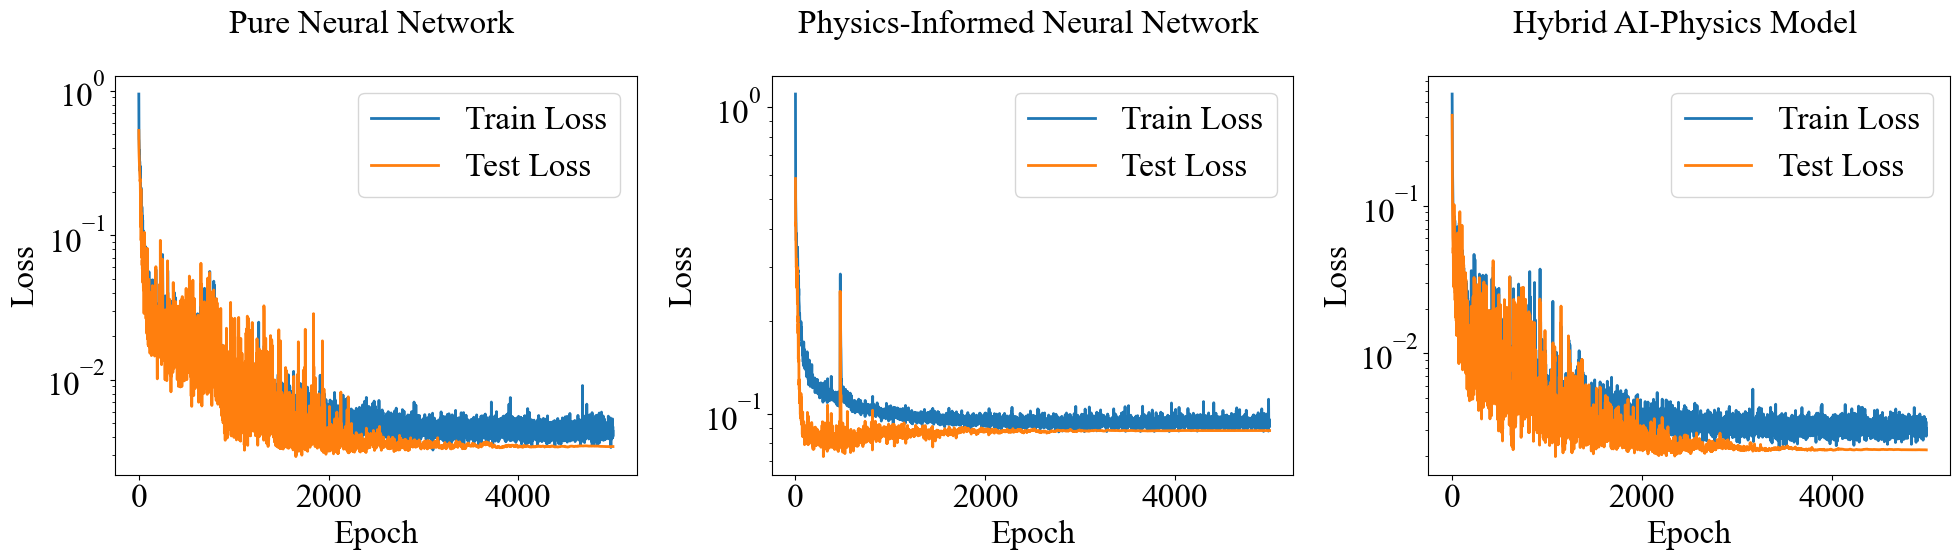

✓ Graph 1: Training curves saved

2. Predictions Comparison (3 models)...


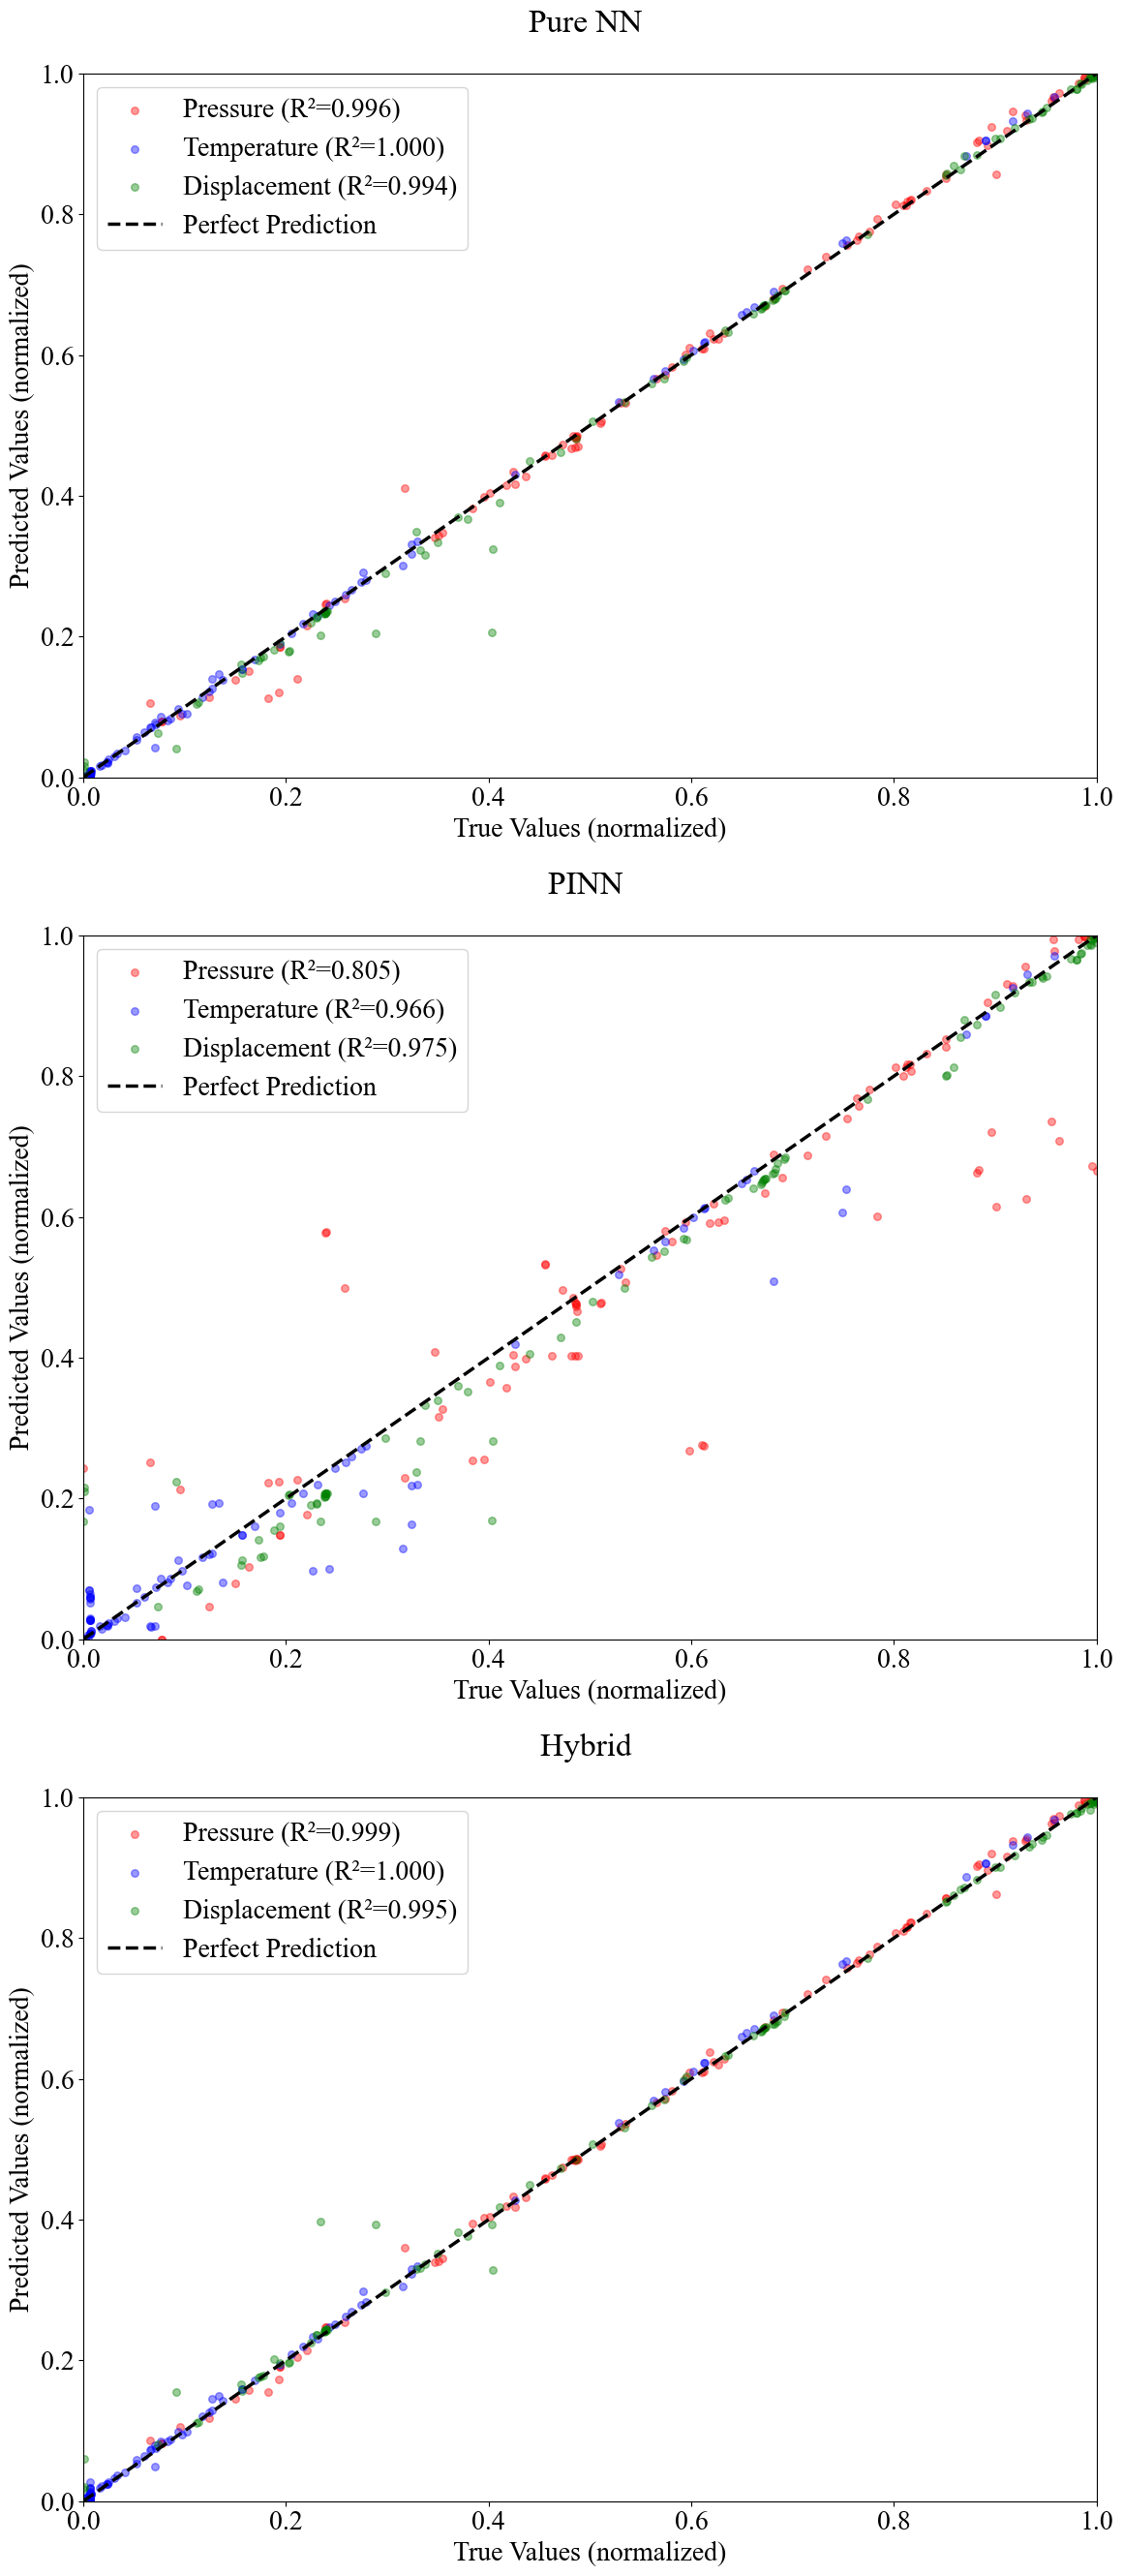

✓ Graph 2: Predictions comparison saved

3. Temporal Profiles (3 outputs at x=2.5m)...


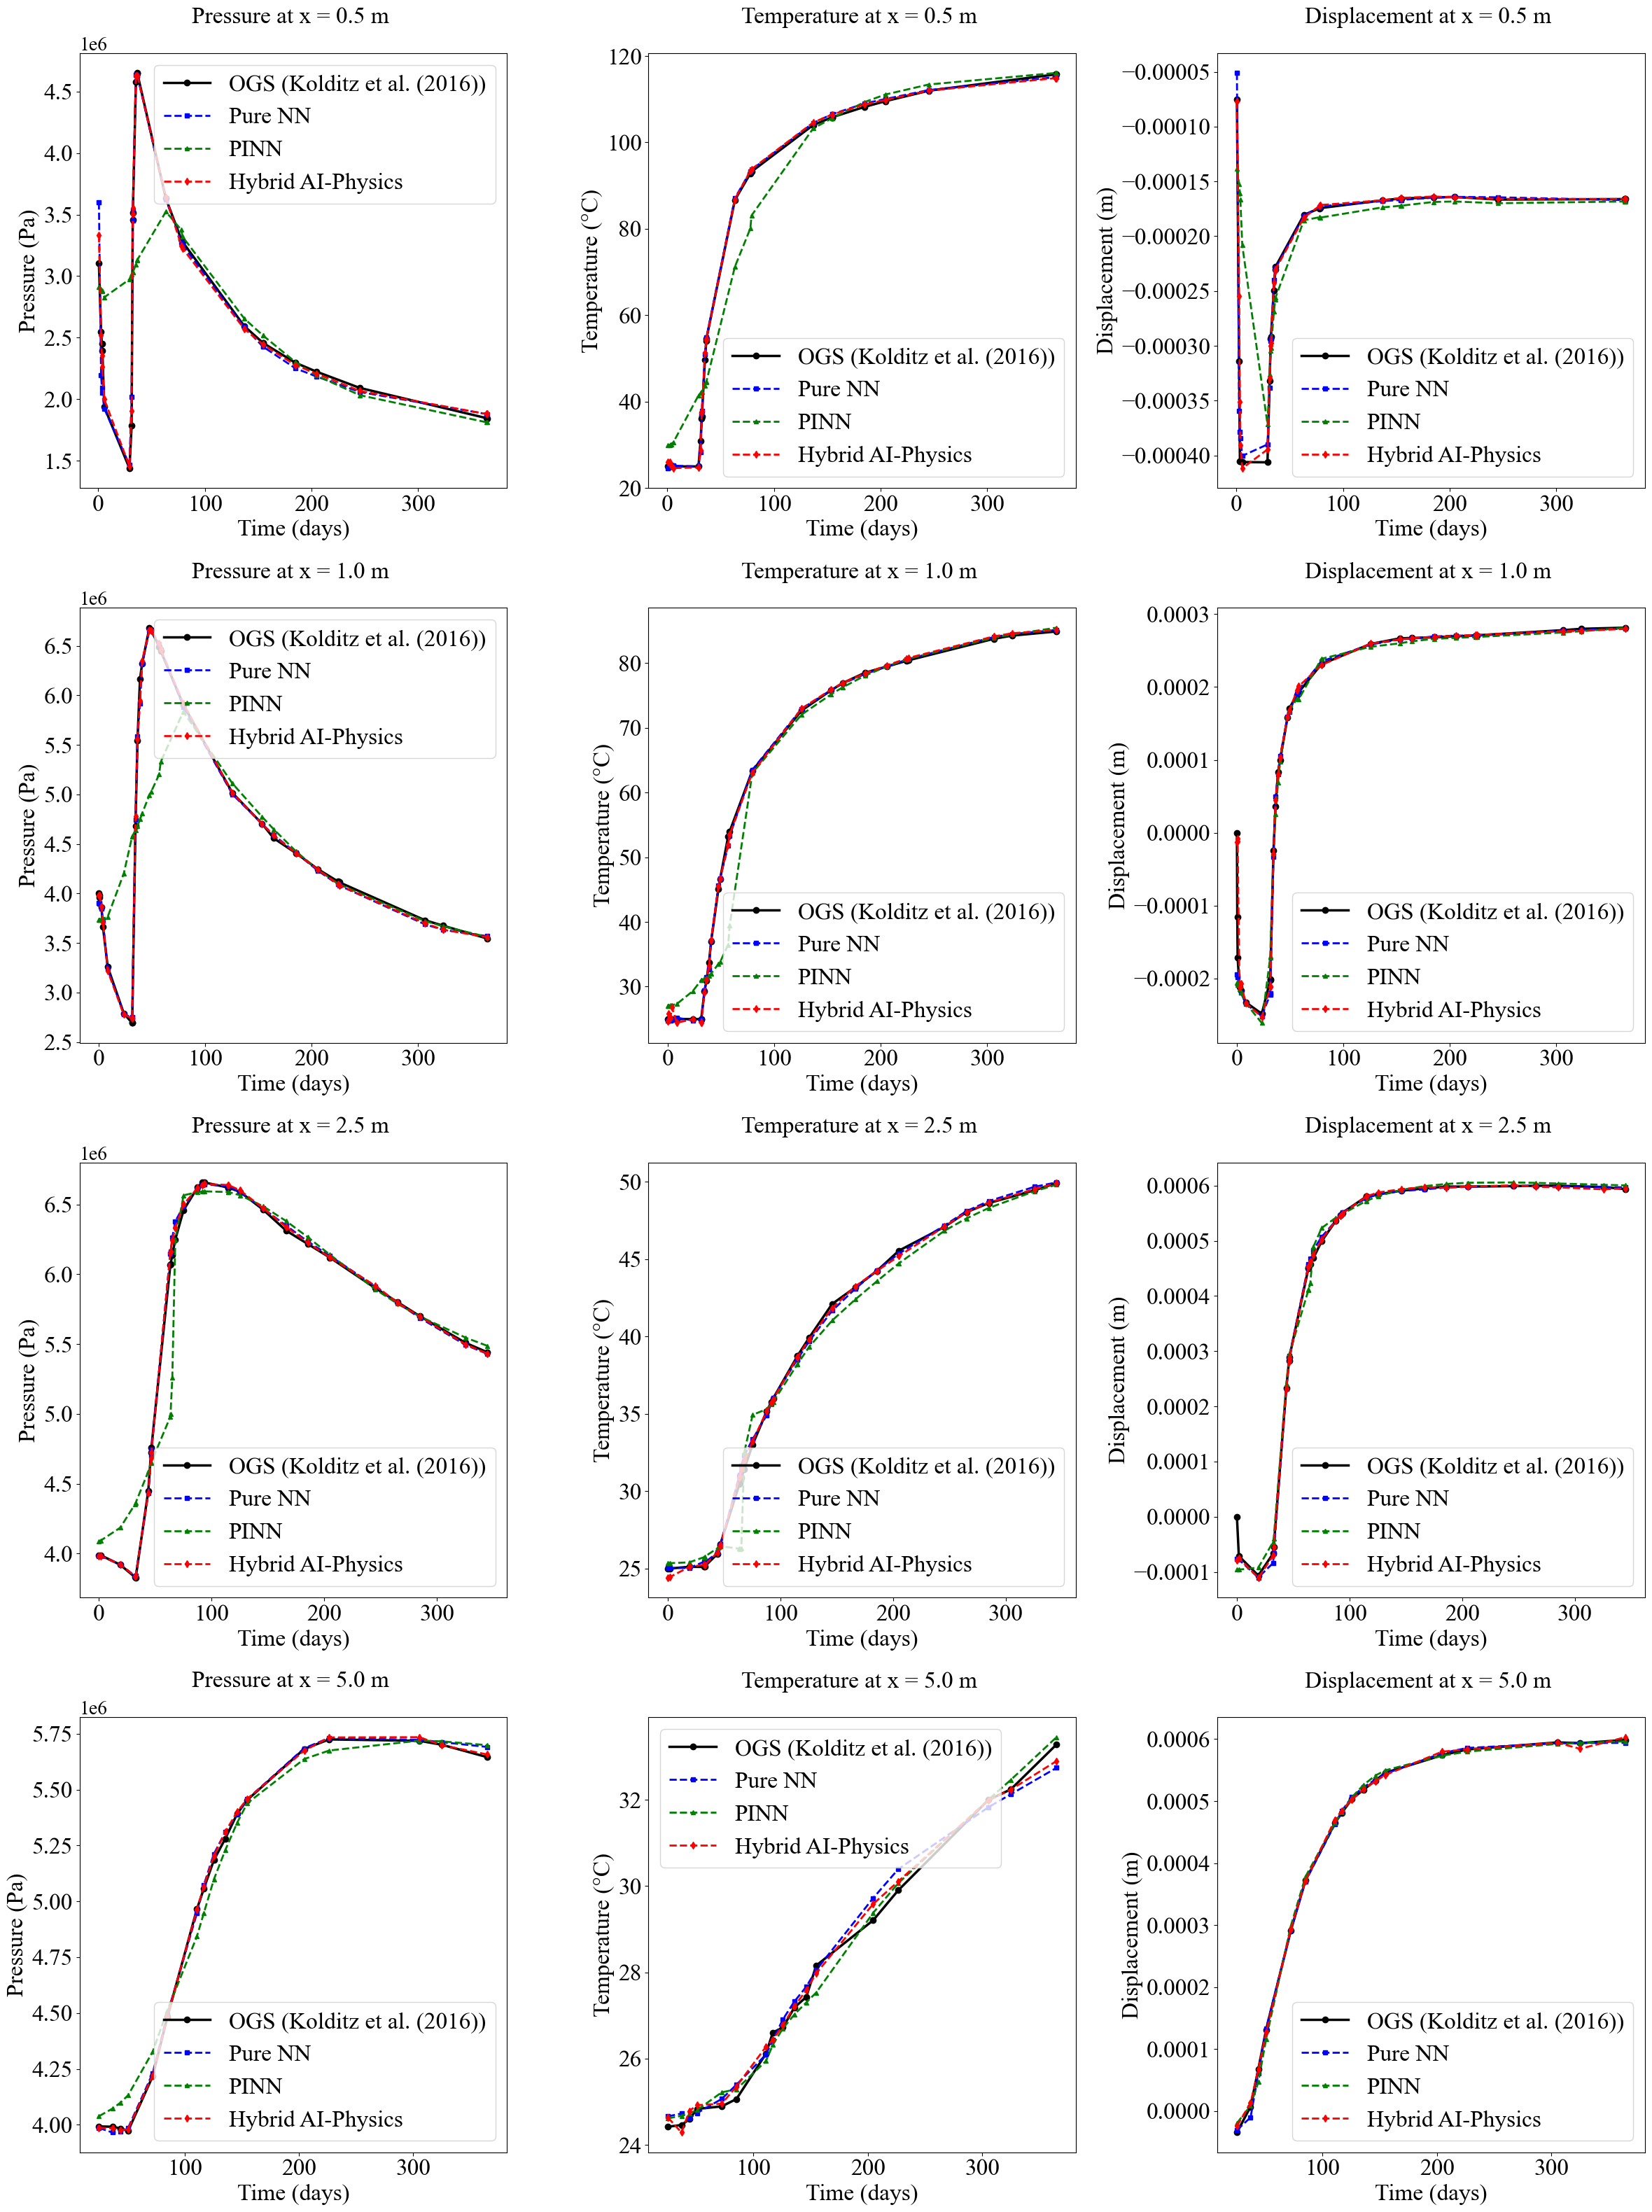

✓ Graph 3: Temporal profiles saved

4. 2D Contour Plots (Hybrid + Differences)...


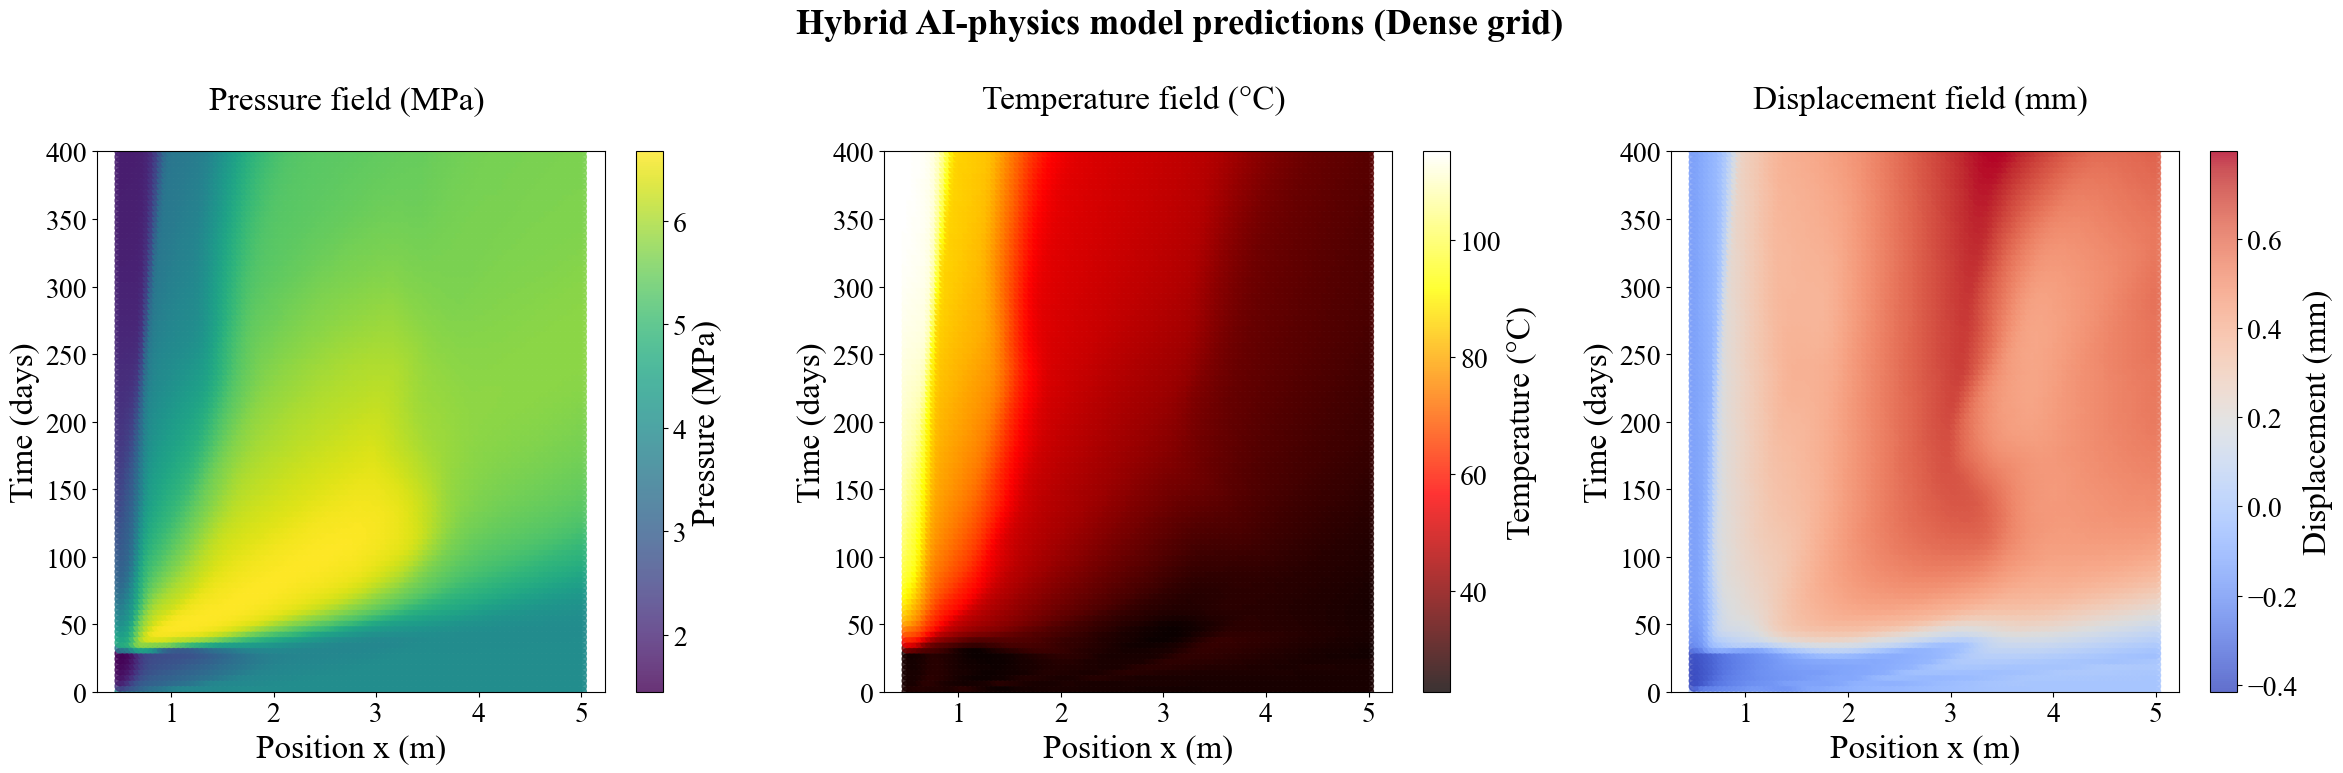

✓ Graph 4: 2D scatter plots on dense grid for Hybrid model generated
  Grid resolution: 100 x 100 = 10000 points

5. Error Analysis (3 models)...


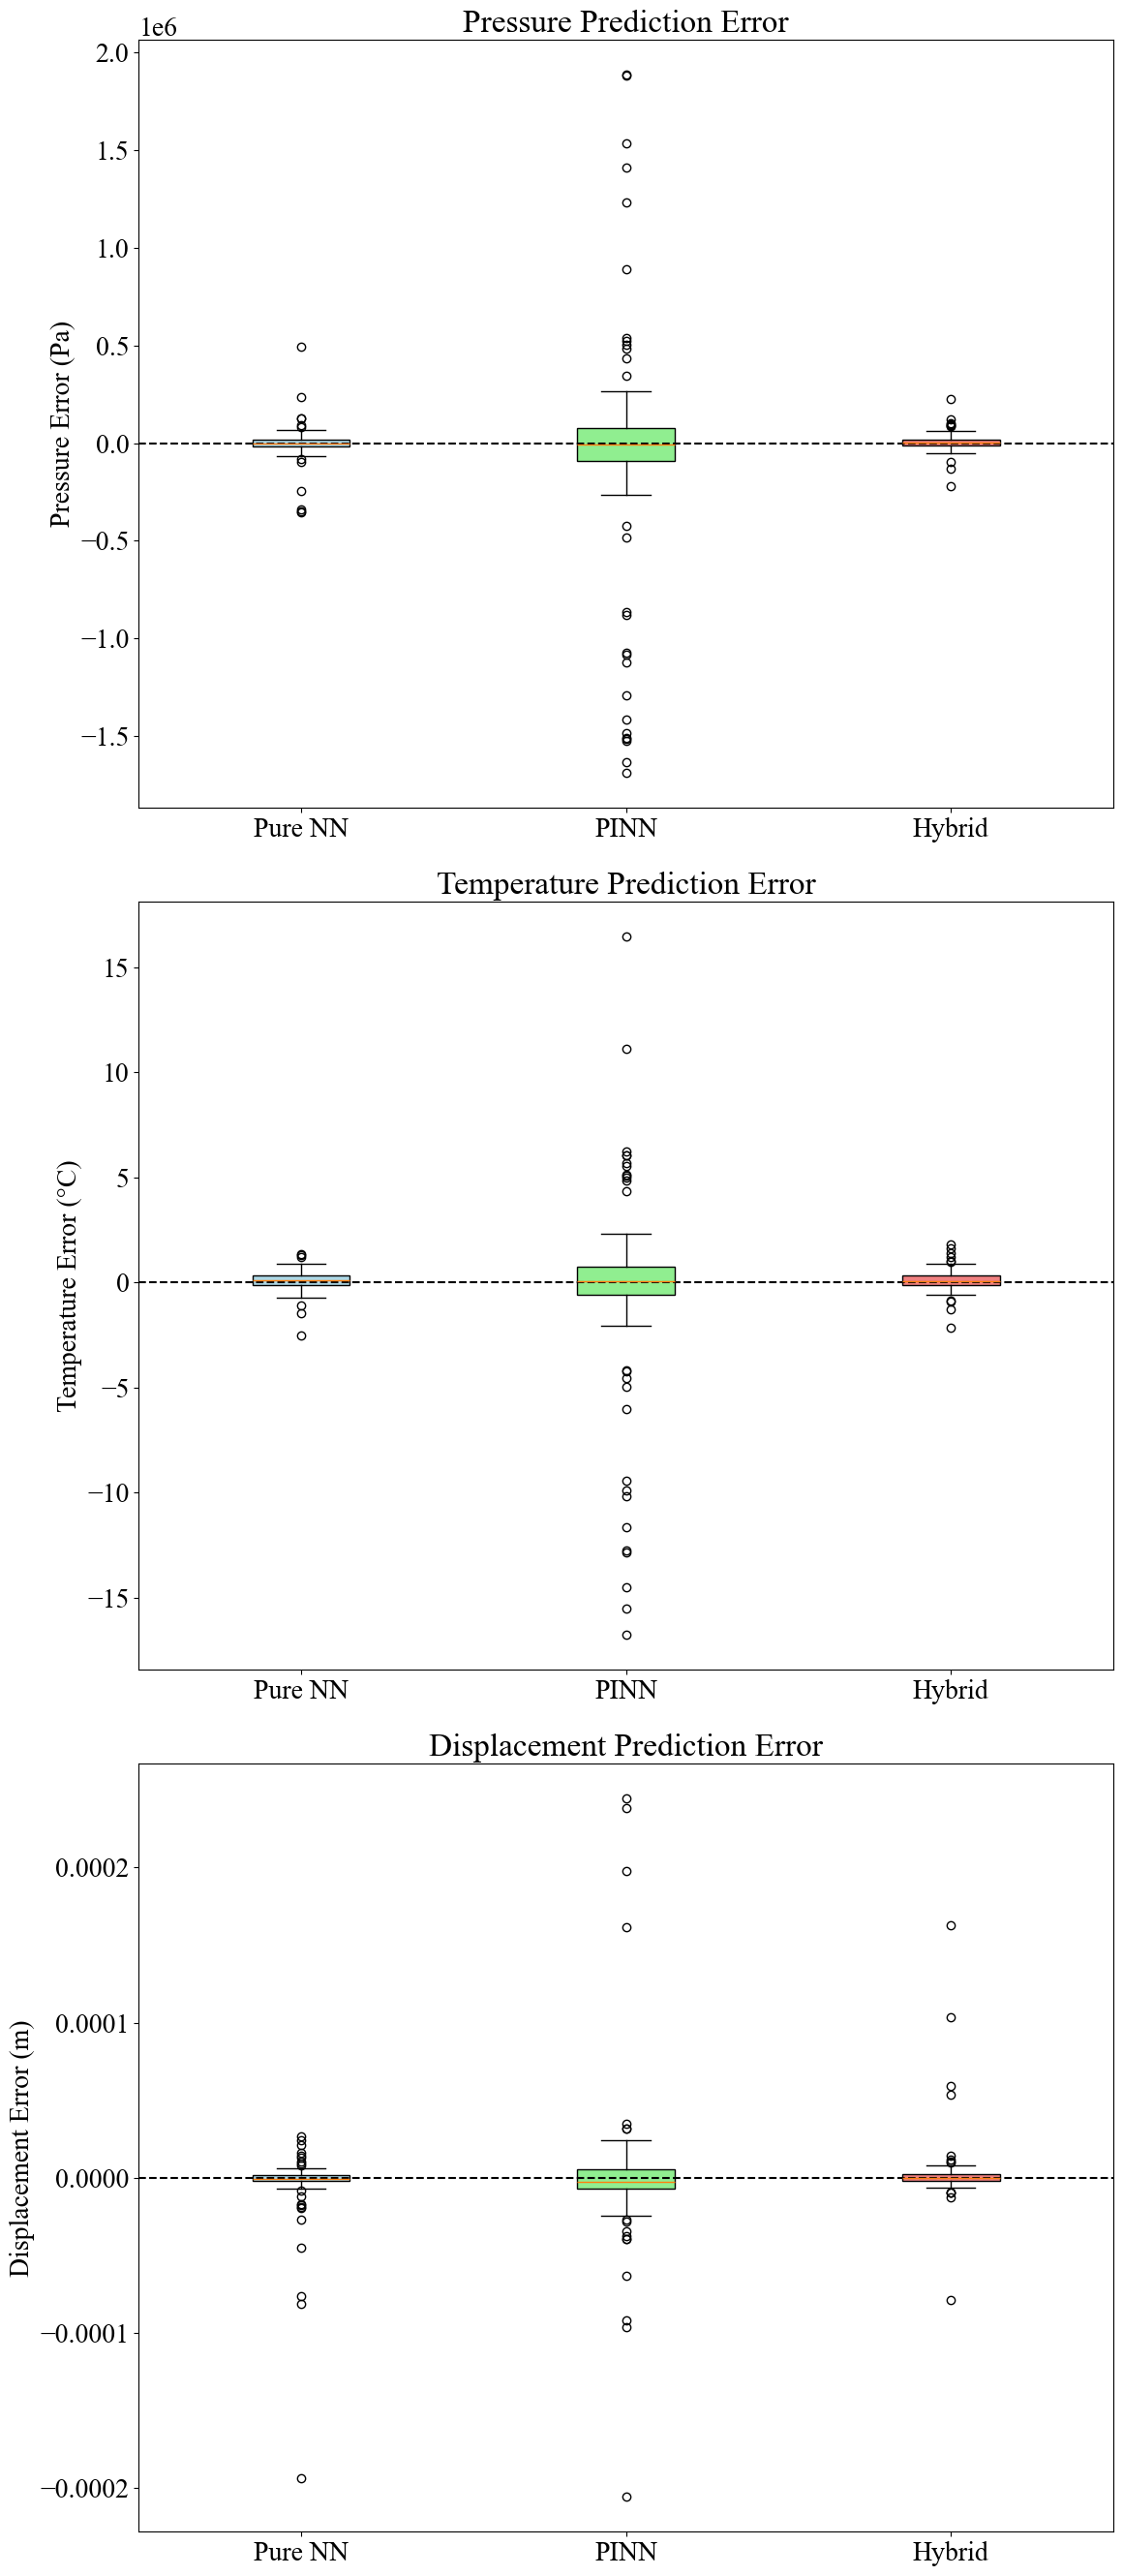

✓ Graph 5: Error analysis saved

6. Performance Summary (3 metrics)...


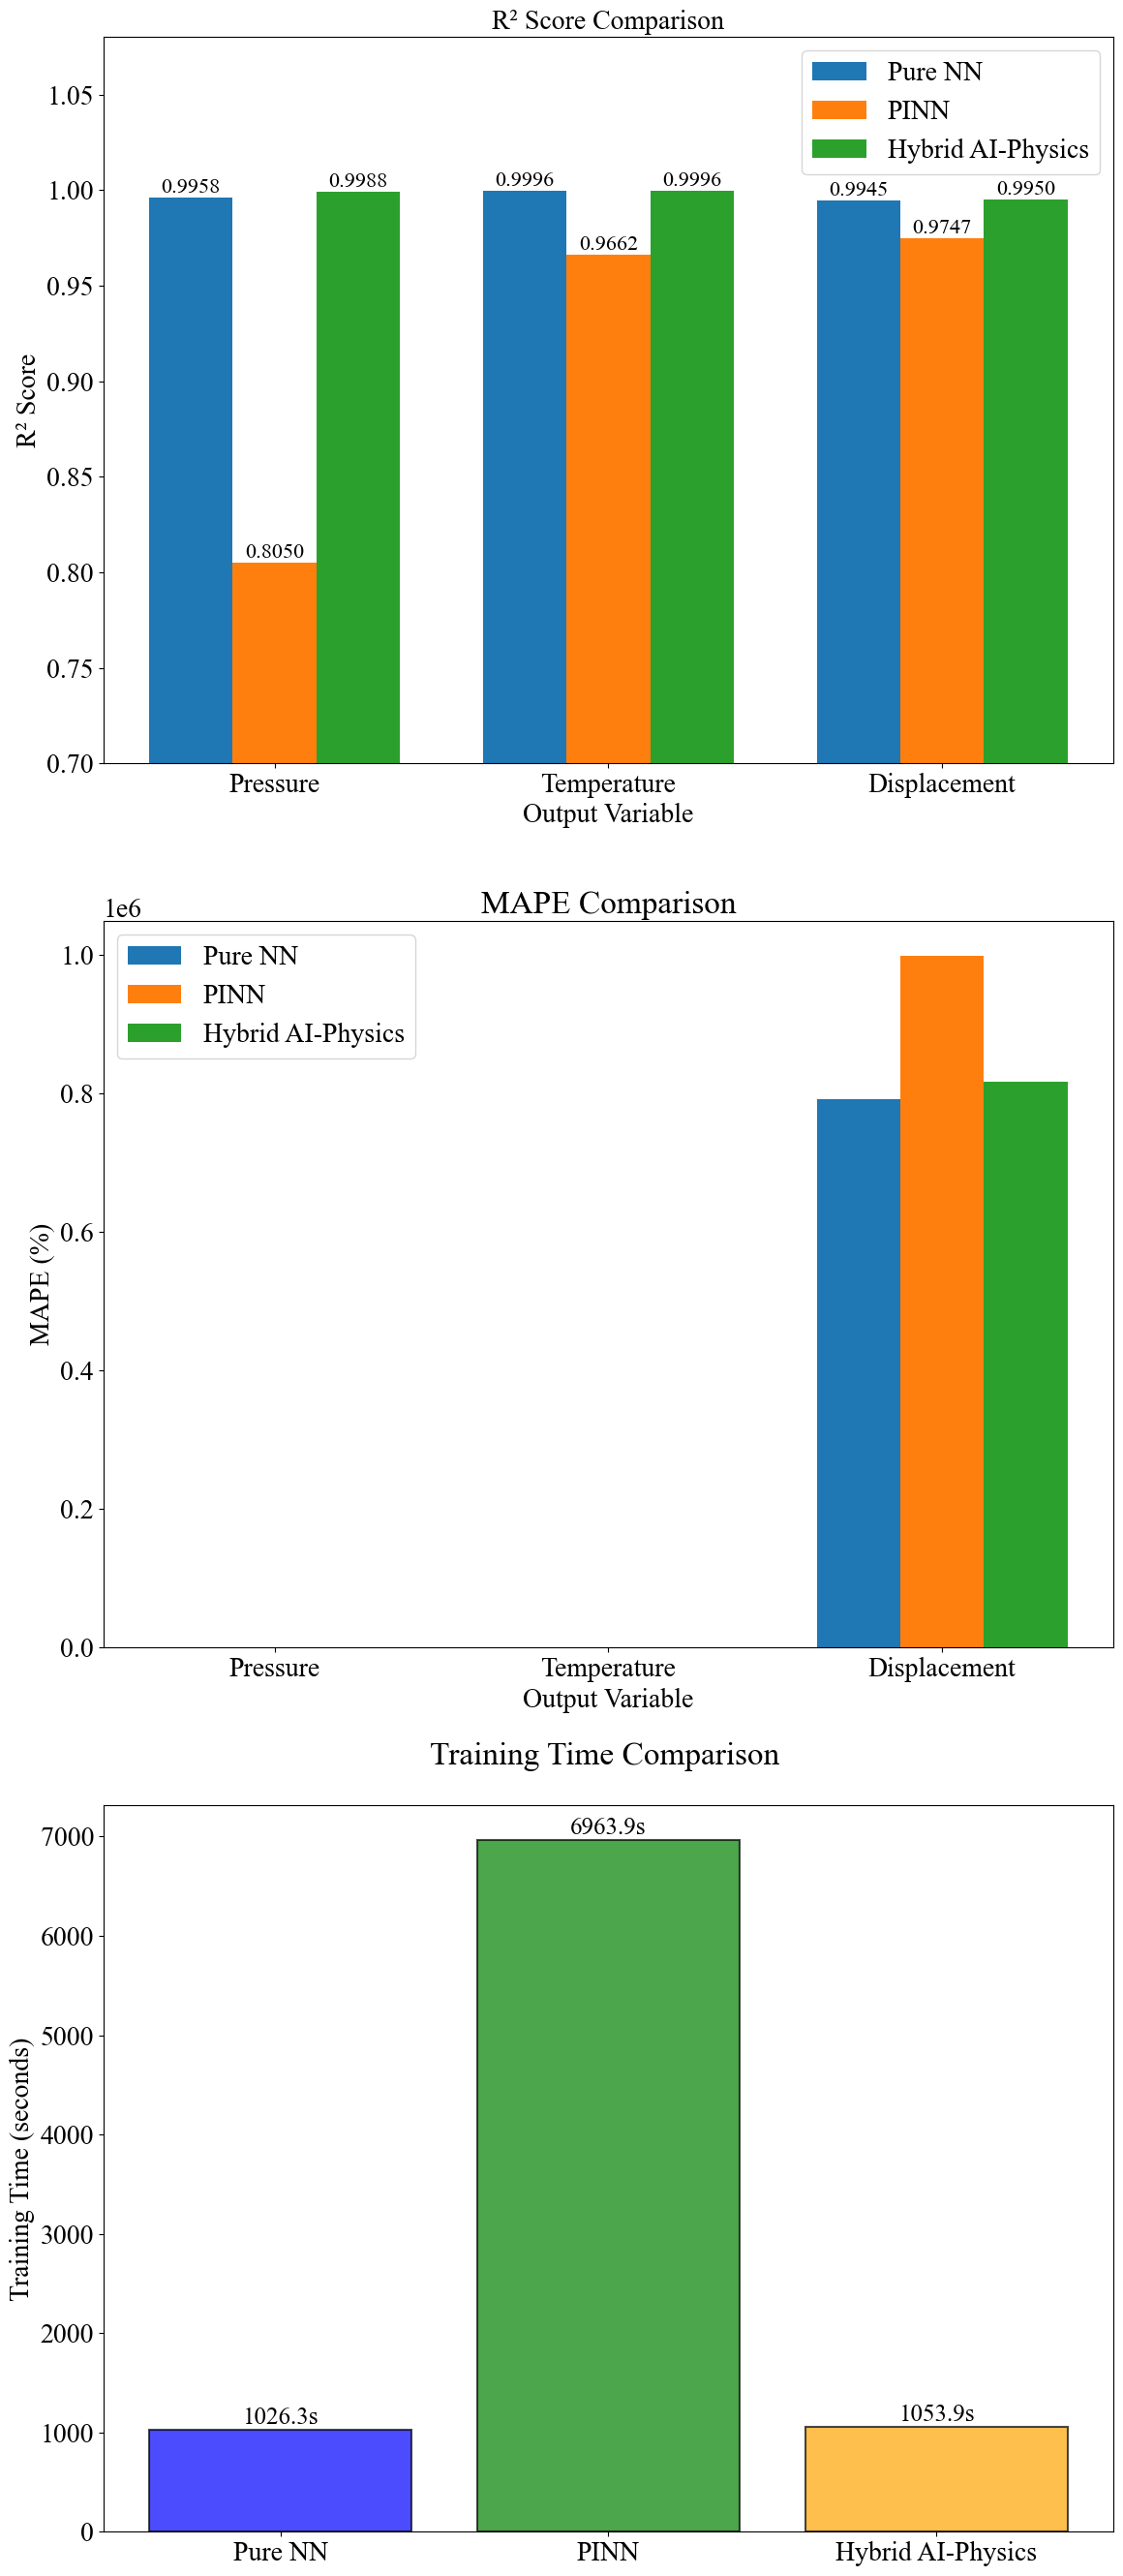

✓ Graph 6: Performance summary saved

✅ ALL VISUALIZATIONS COMPLETE!

Generated 6 files:
  1. 01_training_curves.png
  2. 02_predictions_comparison.png
  3. 03_temporal_profiles.png
  4. 04_spatial_profiles_2d_contour.png (NEW: 2D contour plots)
  5. 05_error_analysis.png
  6. 06_performance_summary.png


In [5]:
print("="*80)
print("REVISING CODE - COMPLETE VISUALIZATION SUITE")
print("="*80)

#============================================================================
# WINDOW 5: VISUALIZATION AND ANALYSIS (FINAL V7) - WITH 2D CONTOUR PLOTS
#============================================================================
# Comprehensive visualization of results comparing all models
# - EXACTLY 6 graphs
# - Graph 4: 2D contour plots (Hybrid predictions + differences)
# - Font: Times New Roman, size 20
# - No bold, no grid (except Graph 4)
#============================================================================

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import griddata
from scipy.spatial import ConvexHull
from matplotlib.path import Path

# ============================================================================
# SET MATPLOTLIB FONT PARAMETERS
# ============================================================================

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 20
plt.rcParams['font.weight'] = 'normal'
plt.rcParams['axes.labelweight'] = 'normal'
plt.rcParams['axes.titleweight'] = 'normal'

# ============================================================================
# VISUALIZATION FUNCTIONS (FINAL V7 - WITH 2D CONTOUR PLOTS)
# ============================================================================

def plot_training_curves():
    """Graph 1: Training curves - 3 rows: 3 models"""
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    
    models_data = [
        (pure_nn_train_losses, pure_nn_test_losses, 'Pure Neural Network \n'),
        (pinn_train_losses, pinn_test_losses, 'Physics-Informed Neural Network \n'),
        (hybrid_train_losses, hybrid_test_losses, 'Hybrid AI-Physics Model \n')
    ]
    
    for ax, (train_loss, test_loss, title) in zip(axes, models_data):
        ax.plot(train_loss, label='Train Loss', linewidth=2)
        ax.plot(test_loss, label='Test Loss', linewidth=2)
        ax.set_xlabel('Epoch', fontsize=24)
        ax.set_ylabel('Loss', fontsize=24)
        ax.set_title(title, fontsize=24)
        ax.legend(fontsize=24)
        ax.tick_params(axis='both', which='major', labelsize=24)
        ax.set_yscale('log')
    
    plt.tight_layout()
    plt.savefig('01_training_curves.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Graph 1: Training curves saved")

def plot_predictions_comparison():
    """Graph 2: Predictions vs true - 3 rows: 3 models"""
    fig, axes = plt.subplots(3, 1, figsize=(12, 27))
    
    model_names = ['Pure NN \n', 'PINN \n', 'Hybrid \n']
    predictions = [pure_nn_pred, pinn_pred, hybrid_pred]
    metrics_list = [pure_nn_metrics, pinn_metrics, hybrid_metrics]
    output_names = ['Pressure', 'Temperature', 'Displacement']
    colors = ['red', 'blue', 'green']
    
    for j, (model_name, pred, metrics) in enumerate(zip(model_names, predictions, metrics_list)):
        ax = axes[j]
        
        # Plot all three outputs with different colors
        for i, (output_name, color) in enumerate(zip(output_names, colors)):
            y_true_i = y_true[:, i]
            y_pred_i = pred[:, i]
            
            # Normalize to [0, 1] for comparison
            y_true_norm = (y_true_i - y_true_i.min()) / (y_true_i.max() - y_true_i.min() + 1e-10)
            y_pred_norm = (y_pred_i - y_pred_i.min()) / (y_pred_i.max() - y_pred_i.min() + 1e-10)
            
            ax.scatter(y_true_norm, y_pred_norm, alpha=0.4, s=30, 
                      label=f'{output_name} (R²={metrics[output_name]["R2"]:.3f})', color=color)
        
        # Perfect prediction line
        ax.plot([0, 1], [0, 1], 'k--', linewidth=2.5, label='Perfect Prediction')
        
        ax.set_xlabel('True Values (normalized)')
        ax.set_ylabel('Predicted Values (normalized)')
        ax.set_title(model_name)
        ax.legend(fontsize=20, loc='best')
        ax.set_xlim([0, 1])
        ax.set_ylim([0, 1])
    
    plt.tight_layout()
    plt.savefig('02_predictions_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Graph 2: Predictions comparison saved")

def plot_temporal_profiles():
    """Graph 3: Temporal profiles at multiple positions - 4 rows (positions) × 3 columns (outputs)"""
    X_test_denorm = scaler_X.inverse_transform(X_test)
    
    # Multiple x positions to plot
    x_targets = [0.5, 1.0, 2.5, 5.0]
    tolerance = 0.1
    
    output_configs = [
        (0, 'Pressure (Pa)', 'Pressure'),
        (1, 'Temperature (°C)', 'Temperature'),
        (2, 'Displacement (m)', 'Displacement')
    ]
    
    # Create 4×3 subplots (4 positions × 3 outputs)
    fig, axes = plt.subplots(4, 3, figsize=(24, 32))
    
    for row_idx, x_target in enumerate(x_targets):
        # Find indices where x ≈ x_target (tolerance: 0.1m)
        mask = np.abs(X_test_denorm[:, 0] - x_target) < tolerance
        
        if np.sum(mask) == 0:
            print(f"⚠ Warning: No data points found near x={x_target}m")
            # Skip this position but keep plot index
            for col_idx in range(3):
                axes[row_idx, col_idx].text(0.5, 0.5, f'No data at x={x_target}m', 
                                           ha='center', va='center', 
                                           transform=axes[row_idx, col_idx].transAxes,
                                           fontsize=24)
                axes[row_idx, col_idx].set_title(f'No data at x={x_target}m', fontsize=24)
            continue
        
        time_days = X_test_denorm[mask, 1]
        sort_idx = np.argsort(time_days)
        time_days = time_days[sort_idx]
        
        for col_idx, (output_idx, ylabel, title) in enumerate(output_configs):
            ax = axes[row_idx, col_idx]
            
            # Extract values at x_target
            y_true_at_x = y_true[mask, output_idx][sort_idx]
            pure_nn_at_x = pure_nn_pred[mask, output_idx][sort_idx]
            pinn_at_x = pinn_pred[mask, output_idx][sort_idx]
            hybrid_at_x = hybrid_pred[mask, output_idx][sort_idx]
            
            # Plot
            ax.plot(time_days, y_true_at_x, 'k-', linewidth=2.5, label='OGS (Kolditz et al. (2016))', marker='o', markersize=6)
            ax.plot(time_days, pure_nn_at_x, 'b--', linewidth=2, label='Pure NN', marker='s', markersize=5)
            ax.plot(time_days, pinn_at_x, 'g--', linewidth=2, label='PINN', marker='^', markersize=5)
            ax.plot(time_days, hybrid_at_x, 'r--', linewidth=2, label='Hybrid AI-Physics', marker='d', markersize=5)
            
            ax.set_xlabel('Time (days)', fontsize=24)
            ax.set_ylabel(ylabel, fontsize=24)
            ax.set_title(f'{title} at x = {x_target} m \n', fontsize=24)
            ax.legend(fontsize=24, loc='best')
            ax.tick_params(labelsize=24)
            #ax.grid(True, alpha=0.3)
            
    plt.tight_layout()
    plt.savefig('03_temporal_profiles.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Graph 3: Temporal profiles saved")




#def plot_spatial_profiles_2d_scatter():
def plot_spatial_profiles_2d_contour():    
    """Scatter plot showing predictions on a dense grid"""
    
    # Create dense grid for smooth visualization
    x_dense = np.linspace(X_test_denorm[:, 0].min(), X_test_denorm[:, 0].max(), 100)
    t_dense = np.linspace(0, 400, 100)  # Fixed time range from 0 to 400 days
    X_grid, T_grid = np.meshgrid(x_dense, t_dense)
    
    # Flatten grid for prediction
    X_dense_flat = np.column_stack([X_grid.ravel(), T_grid.ravel()])
    
    # Normalize dense grid
    X_dense_norm = scaler_X.transform(X_dense_flat)
    
    # Generate predictions on dense grid
    hybrid_model.eval()
    with torch.no_grad():
        X_dense_tensor = torch.FloatTensor(X_dense_norm).to(Config.device)
        pred_dense_norm = hybrid_model(X_dense_tensor, scaler_X, scaler_y)
        pred_dense = scaler_y.inverse_transform(pred_dense_norm.cpu().numpy())
    
    # Create figure
    fig, axes = plt.subplots(1, 3, figsize=(24, 8))
    
    # Pressure
    scatter1 = axes[0].scatter(X_dense_flat[:, 0], X_dense_flat[:, 1], 
                               c=pred_dense[:, 0]/1e6, cmap='viridis', s=50, alpha=0.8)
    axes[0].set_xlabel('Position x (m)', fontsize=24)
    axes[0].set_ylabel('Time (days)', fontsize=24)
    axes[0].set_title('Pressure field (MPa) \n', fontsize=24)
    axes[0].set_ylim(0, 400)  # Set y-axis limit
    cbar1 = plt.colorbar(scatter1, ax=axes[0])
    cbar1.set_label('Pressure (MPa)', fontsize=24)
    cbar1.ax.tick_params(labelsize=20)
    axes[0].tick_params(axis='both', which='major', labelsize=20)
    
    # Temperature
    scatter2 = axes[1].scatter(X_dense_flat[:, 0], X_dense_flat[:, 1], 
                               c=pred_dense[:, 1], cmap='hot', s=50, alpha=0.8)
    axes[1].set_xlabel('Position x (m)', fontsize=24)
    axes[1].set_ylabel('Time (days)', fontsize=24)
    axes[1].set_title('Temperature field (°C) \n', fontsize=24)
    axes[1].set_ylim(0, 400)  # Set y-axis limit
    cbar2 = plt.colorbar(scatter2, ax=axes[1])
    cbar2.set_label('Temperature (°C)', fontsize=24)
    cbar2.ax.tick_params(labelsize=20)
    axes[1].tick_params(axis='both', which='major', labelsize=20)
    
    # Displacement
    scatter3 = axes[2].scatter(X_dense_flat[:, 0], X_dense_flat[:, 1], 
                               c=pred_dense[:, 2]*1e3, cmap='coolwarm', s=50, alpha=0.8)
    axes[2].set_xlabel('Position x (m)', fontsize=24)
    axes[2].set_ylabel('Time (days)', fontsize=24)
    axes[2].set_title('Displacement field (mm) \n', fontsize=24)
    axes[2].set_ylim(0, 400)  # Set y-axis limit
    cbar3 = plt.colorbar(scatter3, ax=axes[2])
    cbar3.set_label('Displacement (mm)', fontsize=24)
    cbar3.ax.tick_params(labelsize=20)
    axes[2].tick_params(axis='both', which='major', labelsize=20)
    
    fig.suptitle('Hybrid AI-physics model predictions (Dense grid)', 
                 fontsize=26, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()
    
    print('✓ Graph 4: 2D scatter plots on dense grid for Hybrid model generated')
    print(f'  Grid resolution: {len(x_dense)} x {len(t_dense)} = {len(X_dense_flat)} points')





def plot_error_analysis():
    """Graph 5: Error analysis - 3 rows: 3 outputs"""
    output_configs = [
        (0, 'Pressure Error (Pa)', 'Pressure'),
        (1, 'Temperature Error (°C)', 'Temperature'),
        (2, 'Displacement Error (m)', 'Displacement')
    ]
    
    fig, axes = plt.subplots(3, 1, figsize=(12, 27))
    
    for idx, (output_idx, ylabel, title) in enumerate(output_configs):
        ax = axes[idx]
        
        # Calculate errors
        pure_nn_error = pure_nn_pred[:, output_idx] - y_true[:, output_idx]
        pinn_error = pinn_pred[:, output_idx] - y_true[:, output_idx]
        hybrid_error = hybrid_pred[:, output_idx] - y_true[:, output_idx]
        
        # Box plot
        data = [pure_nn_error, pinn_error, hybrid_error]
        bp = ax.boxplot(data, labels=['Pure NN', 'PINN', 'Hybrid'], patch_artist=True)
        
        # Color boxes
        colors = ['lightblue', 'lightgreen', 'lightcoral']
        for patch, color in zip(bp['boxes'], colors):
            patch.set_facecolor(color)
        
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1.5)
        ax.set_ylabel(ylabel)
        ax.set_title(f'{title} Prediction Error')
    
    plt.tight_layout()
    plt.savefig('05_error_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Graph 5: Error analysis saved")

def plot_performance_summary():
    """Graph 6: Performance summary - 3 rows: 3 metrics"""
    fig, axes = plt.subplots(3, 1, figsize=(12, 27))
    
    models = ['Pure NN', 'PINN', 'Hybrid AI-Physics']
    output_names = ['Pressure', 'Temperature', 'Displacement']
    metrics_list = [pure_nn_metrics, pinn_metrics, hybrid_metrics]
    
    # R² scores
    ax = axes[0]
    x = np.arange(len(output_names))
    width = 0.25
    
    for i, (model, metrics) in enumerate(zip(models, metrics_list)):
        r2_scores = [metrics[name]['R2'] for name in output_names]
        bars = ax.bar(x + i*width, r2_scores, width, label=model)
        
        # Add R² values on top of bars
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.4f}',
                   ha='center', va='bottom', fontsize=16)
    
    ax.set_xlabel('Output Variable', fontsize=20)
    ax.set_ylabel('R² Score', fontsize=20)
    ax.set_title('R² Score Comparison', fontsize=20)
    ax.set_xticks(x + width)
    ax.set_xticklabels(output_names, fontsize=20)
    ax.legend(fontsize=20)
    ax.set_ylim([0.70, 1.08])
    ax.tick_params(labelsize=20)
    
    # MAPE
    ax = axes[1]
    for i, (model, metrics) in enumerate(zip(models, metrics_list)):
        mape_scores = [metrics[name]['MAPE'] for name in output_names]
        ax.bar(x + i*width, mape_scores, width, label=model)
    
    ax.set_xlabel('Output Variable')
    ax.set_ylabel('MAPE (%)')
    ax.set_title('MAPE Comparison')
    ax.set_xticks(x + width)
    ax.set_xticklabels(output_names)
    ax.legend(fontsize=20)
    
    # Training time
    ax = axes[2]
    training_times = [pure_nn_time, pinn_time, hybrid_time]
    colors_bar = ['blue', 'green', 'orange']
    bars = ax.bar(models, training_times, color=colors_bar, alpha=0.7, edgecolor='black', linewidth=1.5)
    ax.set_ylabel('Training Time (seconds)')
    ax.set_title('Training Time Comparison \n')
    
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.1f}s', ha='center', va='bottom', fontsize=18)
    
    plt.tight_layout()
    plt.savefig('06_performance_summary.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Graph 6: Performance summary saved")

# ============================================================================
# GENERATE ALL VISUALIZATIONS
# ============================================================================

print("\n" + "="*80)
print("STEP 4: GENERATING VISUALIZATIONS (WITH 2D CONTOUR PLOTS)")
print("="*80)

print("\n1. Training Curves (3 models)...")
plot_training_curves()

print("\n2. Predictions Comparison (3 models)...")
plot_predictions_comparison()

print("\n3. Temporal Profiles (3 outputs at x=2.5m)...")
plot_temporal_profiles()

print("\n4. 2D Contour Plots (Hybrid + Differences)...")
plot_spatial_profiles_2d_contour()

print("\n5. Error Analysis (3 models)...")
plot_error_analysis()

print("\n6. Performance Summary (3 metrics)...")
plot_performance_summary()

print("\n" + "="*80)
print("✅ ALL VISUALIZATIONS COMPLETE!")
print("="*80)
print("\nGenerated 6 files:")
print("  1. 01_training_curves.png")
print("  2. 02_predictions_comparison.png")
print("  3. 03_temporal_profiles.png")
print("  4. 04_spatial_profiles_2d_contour.png (NEW: 2D contour plots)")
print("  5. 05_error_analysis.png")
print("  6. 06_performance_summary.png")
print("="*80)


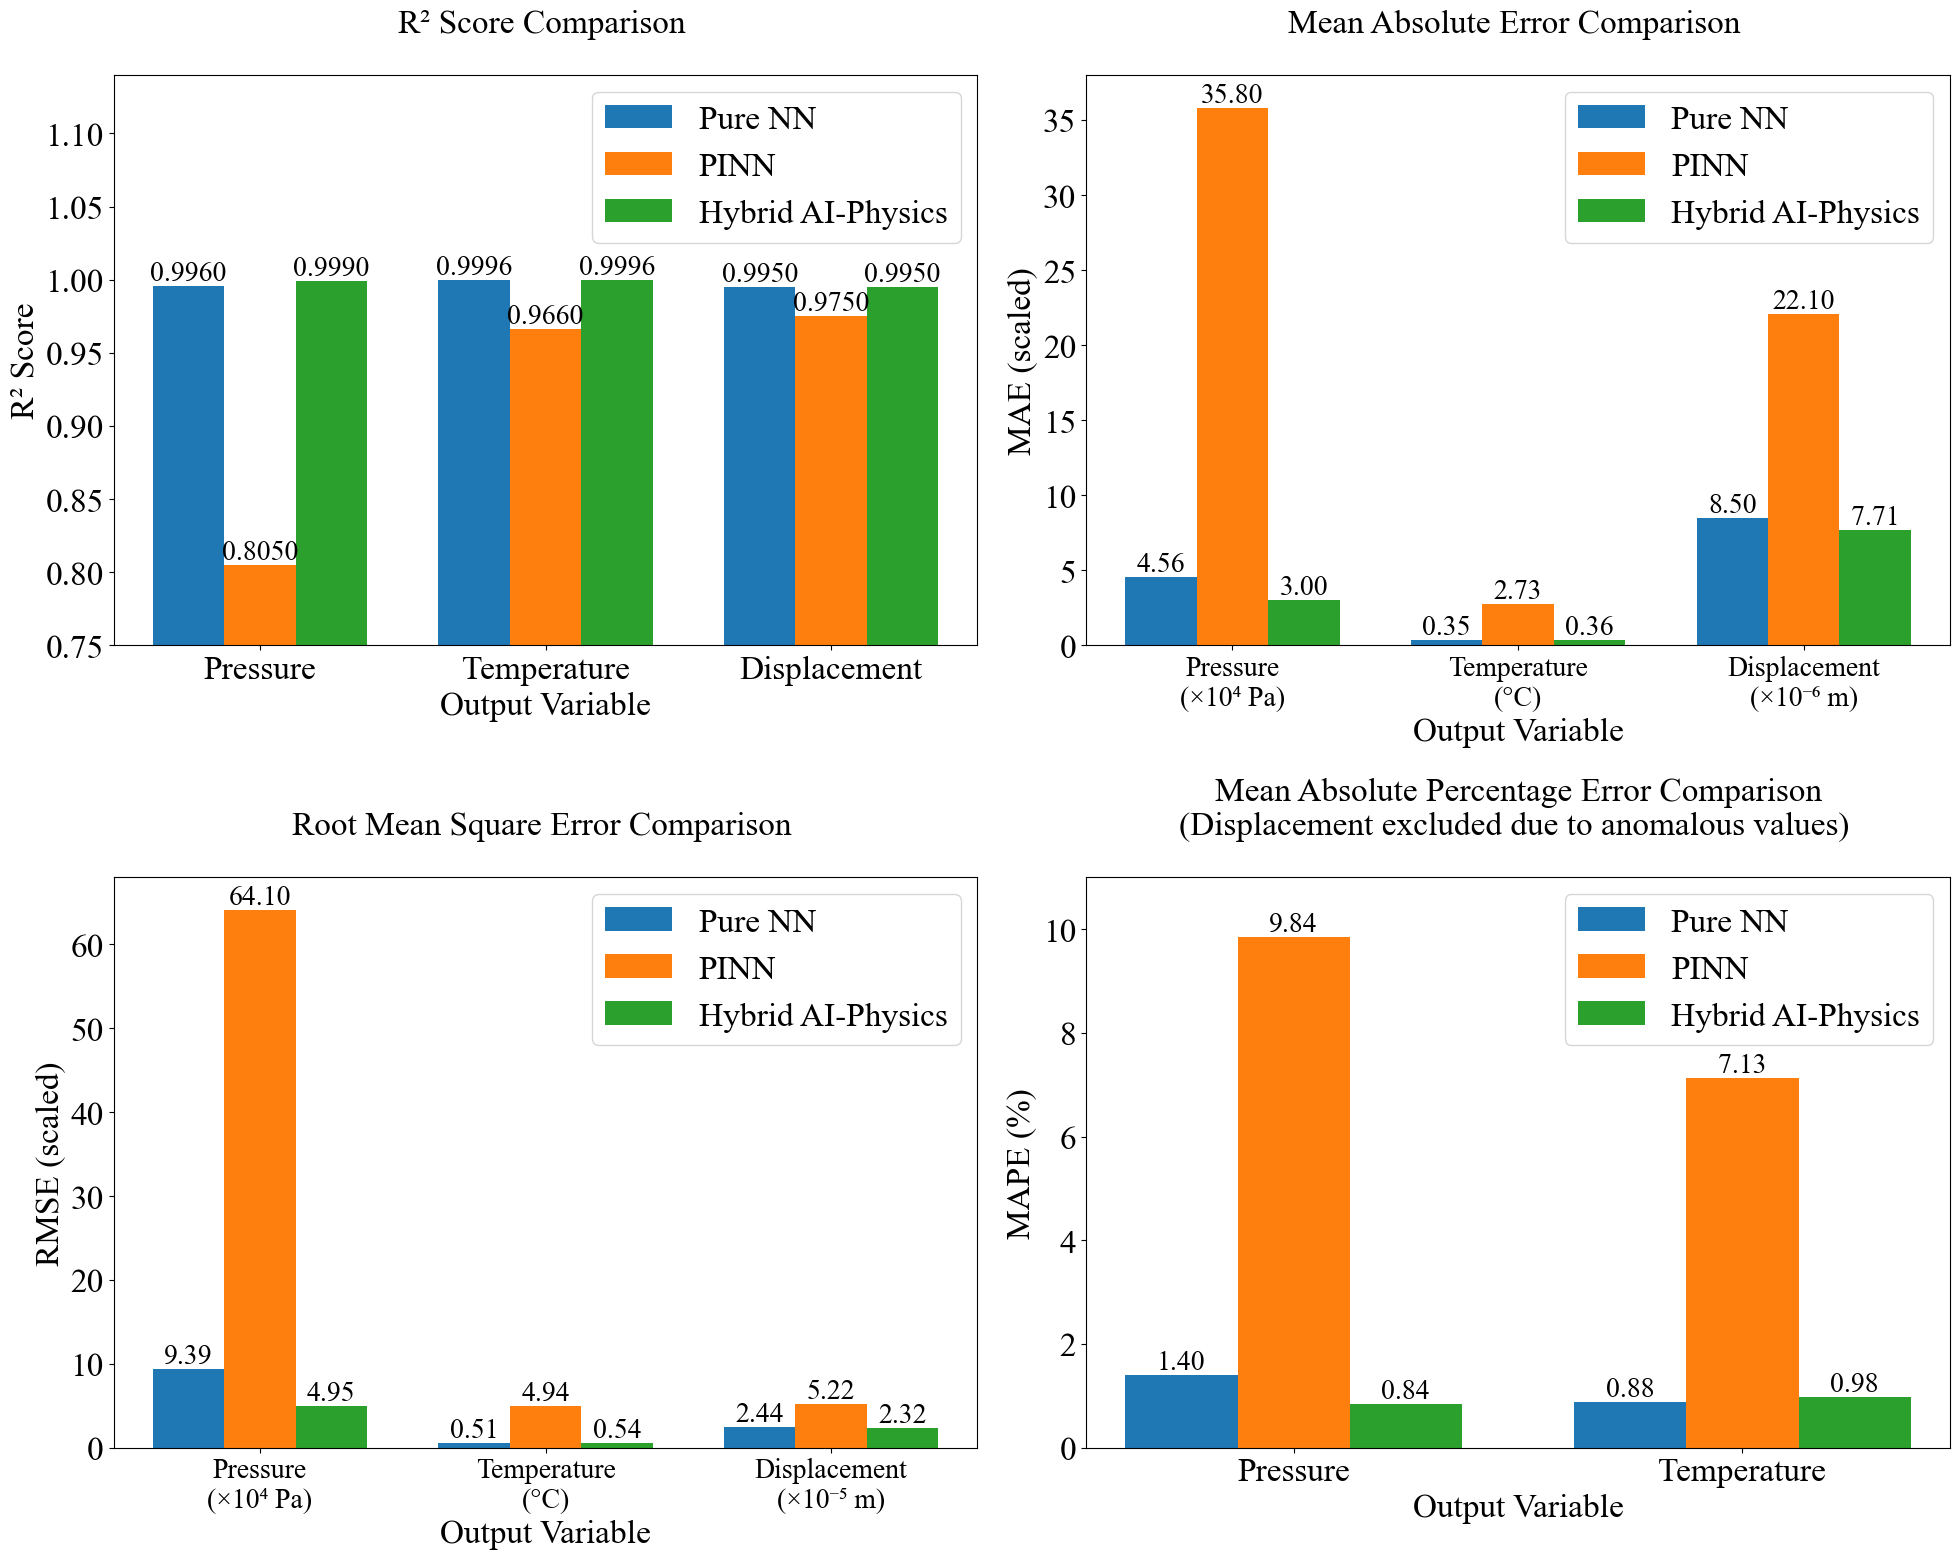

✓ Performance metrics comparison saved


In [6]:
import matplotlib.pyplot as plt
import numpy as np

def plot_performance_metrics():
    """Plot performance metrics comparison for three models"""
    
    # Data for three models (excluding Physics-Only)
    models = ['Pure NN', 'PINN', 'Hybrid AI-Physics']
    outputs = ['Pressure', 'Temperature', 'Displacement']
    
    # R² values (4 decimal places)
    r2_data = {
        'Pressure': [0.9960, 0.8050, 0.9990],
        'Temperature': [0.9996, 0.9660, 0.9996],
        'Displacement': [0.9950, 0.9750, 0.9950]
    }
    
    # MAE values
    mae_data = {
        'Pressure': [4.56e4, 3.58e5, 3.00e4],  # Pa
        'Temperature': [0.35, 2.73, 0.36],  # °C
        'Displacement': [8.50e-6, 2.21e-5, 7.71e-6]  # m
    }
    
    # RMSE values
    rmse_data = {
        'Pressure': [9.39e4, 6.41e5, 4.95e4],  # Pa
        'Temperature': [0.51, 4.94, 0.54],  # °C
        'Displacement': [2.44e-5, 5.22e-5, 2.32e-5]  # m
    }
    
    # MAPE values (%)
    mape_data = {
        'Pressure': [1.40, 9.84, 0.84],
        'Temperature': [0.88, 7.13, 0.98],
        'Displacement': [792468, 998969, 816653]
    }
    
    # Create figure with 4 subplots
    fig, axes = plt.subplots(2, 2, figsize=(20, 16))
    
    # Colors for each model
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
    
    # Plot 1: R² Score
    ax1 = axes[0, 0]
    x = np.arange(len(outputs))
    width = 0.25
    
    for i, model in enumerate(models):
        values = [r2_data[output][i] for output in outputs]
        bars = ax1.bar(x + i*width, values, width, label=model, color=colors[i])
        # Add value labels on bars with 4 decimal places
        for bar in bars:
            height = bar.get_height()
            ax1.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.4f}',
                    ha='center', va='bottom', fontsize=20)
    
    ax1.set_xlabel('Output Variable', fontsize=24)
    ax1.set_ylabel('R² Score', fontsize=24)
    ax1.set_title('R² Score Comparison \n', fontsize=24)
    ax1.set_xticks(x + width)
    ax1.set_xticklabels(outputs, fontsize=24)
    ax1.legend(fontsize=24)
    ax1.tick_params(axis='y', labelsize=24)
    ax1.set_ylim([0.75, 1.14])
    #ax1.grid(axis='y', alpha=0.3)
    
    # Plot 2: MAE
    ax2 = axes[0, 1]
    mae_labels = ['Pressure\n(×10⁴ Pa)', 'Temperature\n(°C)', 'Displacement\n(×10⁻⁶ m)']
    mae_scaled = {
        'Pressure': [val/1e4 for val in mae_data['Pressure']],
        'Temperature': mae_data['Temperature'],
        'Displacement': [val*1e6 for val in mae_data['Displacement']]
    }
    
    for i, model in enumerate(models):
        values = [mae_scaled[output][i] for output in outputs]
        bars = ax2.bar(x + i*width, values, width, label=model, color=colors[i])
        # Add value labels on bars
        for j, bar in enumerate(bars):
            height = bar.get_height()
            ax2.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.2f}',
                    ha='center', va='bottom', fontsize=20)
    
    ax2.set_xlabel('Output Variable', fontsize=24)
    ax2.set_ylabel('MAE (scaled)', fontsize=24)
    ax2.set_title('Mean Absolute Error Comparison \n', fontsize=24)
    ax2.set_xticks(x + width)
    ax2.set_xticklabels(mae_labels, fontsize=20)
    ax2.legend(fontsize=24)
    ax2.tick_params(axis='y', labelsize=24)
    ax2.set_ylim([0, 38])
    #ax2.grid(axis='y', alpha=0.3)
    
    # Plot 3: RMSE
    ax3 = axes[1, 0]
    rmse_labels = ['Pressure\n(×10⁴ Pa)', 'Temperature\n(°C)', 'Displacement\n(×10⁻⁵ m)']
    rmse_scaled = {
        'Pressure': [val/1e4 for val in rmse_data['Pressure']],
        'Temperature': rmse_data['Temperature'],
        'Displacement': [val*1e5 for val in rmse_data['Displacement']]
    }
    
    for i, model in enumerate(models):
        values = [rmse_scaled[output][i] for output in outputs]
        bars = ax3.bar(x + i*width, values, width, label=model, color=colors[i])
        # Add value labels on bars
        for j, bar in enumerate(bars):
            height = bar.get_height()
            ax3.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.2f}',
                    ha='center', va='bottom', fontsize=20)
    
    ax3.set_xlabel('Output Variable', fontsize=24)
    ax3.set_ylabel('RMSE (scaled)', fontsize=24)
    ax3.set_title('Root Mean Square Error Comparison \n', fontsize=24)
    ax3.set_xticks(x + width)
    ax3.set_xticklabels(rmse_labels, fontsize=20)
    ax3.legend(fontsize=24)
    ax3.tick_params(axis='y', labelsize=24)
    ax3.set_ylim([0, 68])
    #ax3.grid(axis='y', alpha=0.3)
    
    # Plot 4: MAPE (log scale for displacement)
    ax4 = axes[1, 1]
    # Plot Pressure and Temperature normally
    x_limited = np.arange(2)  # Only Pressure and Temperature
    
    for i, model in enumerate(models):
        values = [mape_data['Pressure'][i], mape_data['Temperature'][i]]
        bars = ax4.bar(x_limited + i*width, values, width, label=model, color=colors[i])
        # Add value labels on bars
        for bar in bars:
            height = bar.get_height()
            ax4.text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.2f}',
                    ha='center', va='bottom', fontsize=20)
    
    ax4.set_xlabel('Output Variable', fontsize=24)
    ax4.set_ylabel('MAPE (%)', fontsize=24)
    ax4.set_title('Mean Absolute Percentage Error Comparison\n(Displacement excluded due to anomalous values) \n', fontsize=24)
    ax4.set_xticks(x_limited + width)
    ax4.set_xticklabels(['Pressure', 'Temperature'], fontsize=24)
    ax4.legend(fontsize=24)
    ax4.tick_params(axis='y', labelsize=24)
    ax4.set_ylim([0, 11])
    #ax4.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('performance_metrics_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Performance metrics comparison saved")

# Call the function
plot_performance_metrics()


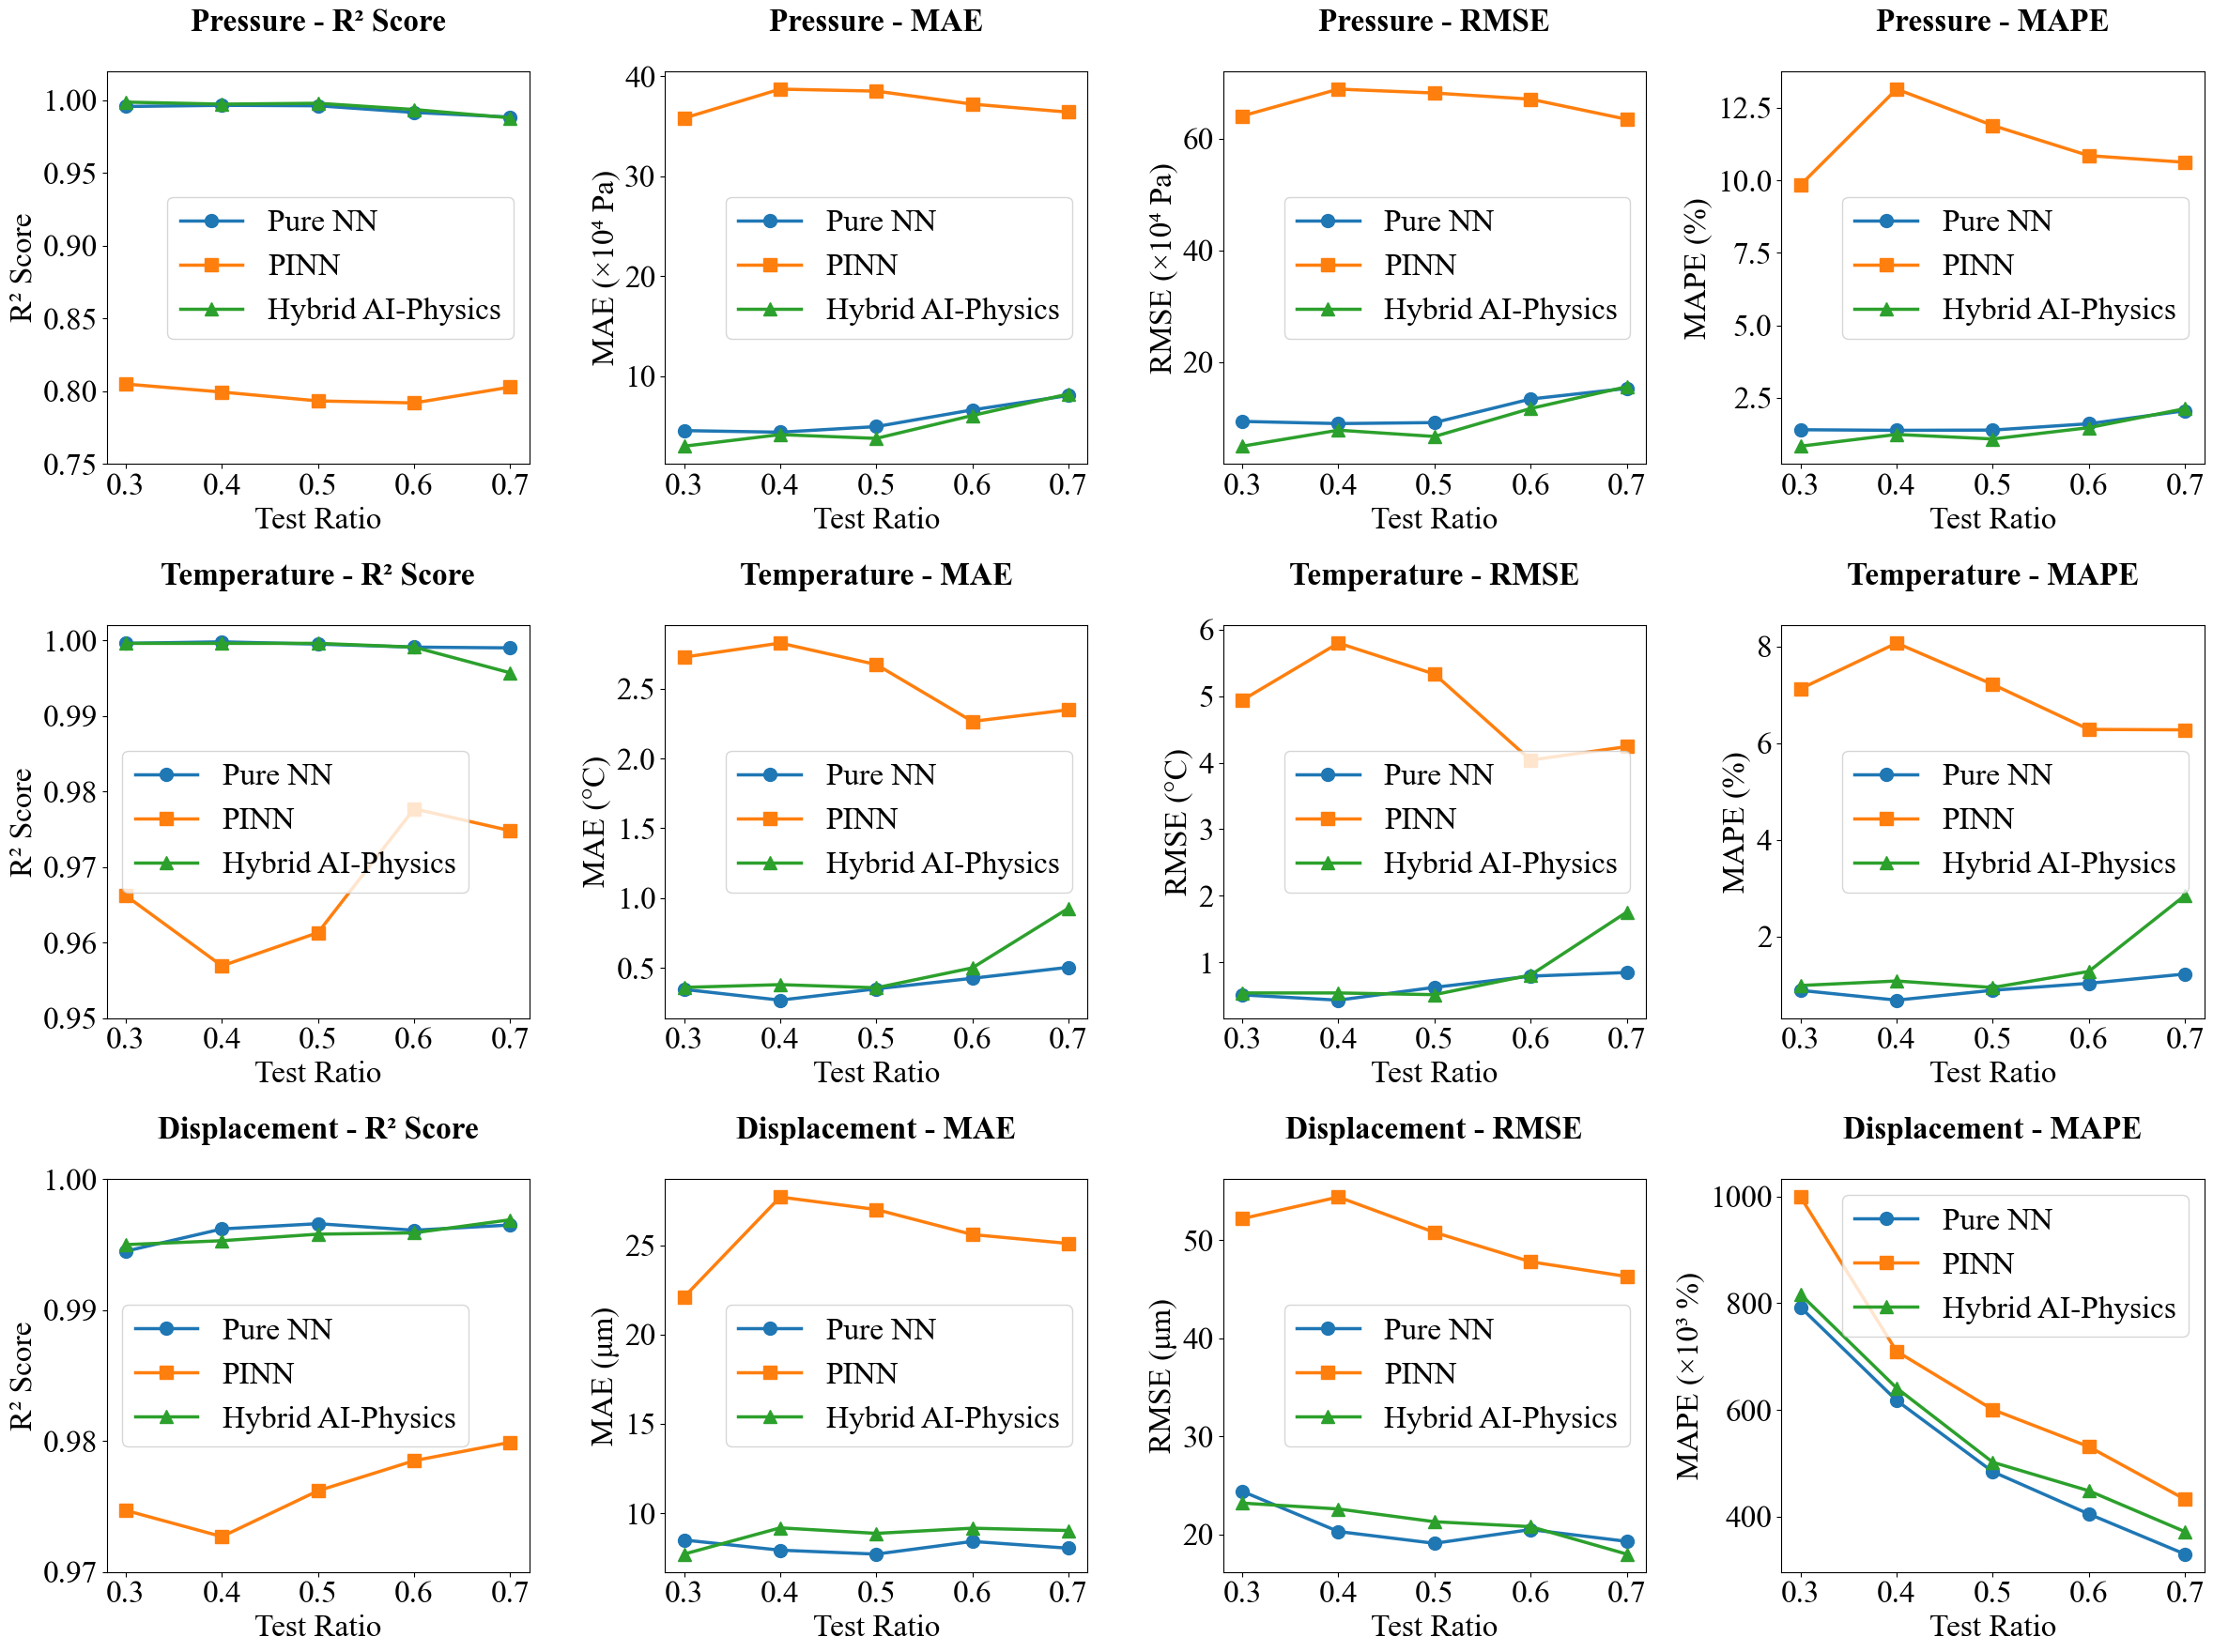

✓ Performance metrics comparison saved


In [7]:

import matplotlib.pyplot as plt
import numpy as np

def plot_performance_metrics_across_test_ratios():
    """Plot performance metrics comparison for three models across different test ratios"""
    
    # Set Times New Roman font
    plt.rcParams['font.family'] = 'serif'
    plt.rcParams['font.serif'] = ['Times New Roman']
    plt.rcParams['mathtext.fontset'] = 'custom'
    plt.rcParams['mathtext.rm'] = 'Times New Roman'
    
    # Data for three models (excluding Physics-Only)
    models = ['Pure NN', 'PINN', 'Hybrid AI-Physics']
    test_ratios = [0.3, 0.4, 0.5, 0.6, 0.7]
    
    # R² values for each test ratio
    r2_data = {
        'Pressure': {
            'Pure NN': [0.9958, 0.9966, 0.9963, 0.9917, 0.9885],
            'PINN': [0.8050, 0.7995, 0.7934, 0.7920, 0.8029],
            'Hybrid AI-Physics': [0.9988, 0.9974, 0.9980, 0.9937, 0.9880]
        },
        'Temperature': {
            'Pure NN': [0.9996, 0.9998, 0.9995, 0.9991, 0.9990],
            'PINN': [0.9662, 0.9569, 0.9613, 0.9777, 0.9748],
            'Hybrid AI-Physics': [0.9996, 0.9996, 0.9996, 0.9991, 0.9957]
        },
        'Displacement': {
            'Pure NN': [0.9945, 0.9962, 0.9966, 0.9961, 0.9965],
            'PINN': [0.9747, 0.9727, 0.9762, 0.9785, 0.9799],
            'Hybrid AI-Physics': [0.9950, 0.9953, 0.9958, 0.9959, 0.9969]
        }
    }
    
    # MAE values
    mae_data = {
        'Pressure': {  # in Pa, will be scaled to 10^4 Pa
            'Pure NN': [4.56e4, 4.40e4, 4.96e4, 6.63e4, 8.07e4],
            'PINN': [3.58e5, 3.87e5, 3.85e5, 3.72e5, 3.64e5],
            'Hybrid AI-Physics': [3.00e4, 4.16e4, 3.78e4, 6.07e4, 8.22e4]
        },
        'Temperature': {  # in °C
            'Pure NN': [0.3458, 0.2685, 0.3494, 0.4252, 0.5038],
            'PINN': [2.7265, 2.8272, 2.6736, 2.2659, 2.3494],
            'Hybrid AI-Physics': [0.3598, 0.3797, 0.3571, 0.4999, 0.9269]
        },
        'Displacement': {  # in m, will be scaled to μm (10^-6 m)
            'Pure NN': [8.50e-6, 7.93e-6, 7.71e-6, 8.42e-6, 8.04e-6],
            'PINN': [2.21e-5, 2.77e-5, 2.70e-5, 2.56e-5, 2.51e-5],
            'Hybrid AI-Physics': [7.71e-6, 9.18e-6, 8.87e-6, 9.16e-6, 9.03e-6]
        }
    }
    
    # RMSE values
    rmse_data = {
        'Pressure': {  # in Pa, will be scaled to 10^4 Pa
            'Pure NN': [9.39e4, 9.00e4, 9.18e4, 1.34e5, 1.53e5],
            'PINN': [6.41e5, 6.89e5, 6.82e5, 6.71e5, 6.35e5],
            'Hybrid AI-Physics': [4.95e4, 7.82e4, 6.69e4, 1.17e5, 1.56e5]
        },
        'Temperature': {  # in °C
            'Pure NN': [0.5119, 0.4326, 0.6251, 0.7934, 0.8480],
            'PINN': [4.9393, 5.7964, 5.3305, 4.0390, 4.2409],
            'Hybrid AI-Physics': [0.5406, 0.5407, 0.5151, 0.8097, 1.7545]
        },
        'Displacement': {  # in m, will be scaled to μm (10^-6 m)
            'Pure NN': [2.44e-5, 2.03e-5, 1.91e-5, 2.05e-5, 1.93e-5],
            'PINN': [5.22e-5, 5.44e-5, 5.08e-5, 4.78e-5, 4.63e-5],
            'Hybrid AI-Physics': [2.32e-5, 2.26e-5, 2.13e-5, 2.08e-5, 1.80e-5]
        }
    }
    
    # MAPE values (%)
    mape_data = {
        'Pressure': {
            'Pure NN': [1.4035, 1.3826, 1.3919, 1.6101, 2.0579],
            'PINN': [9.8402, 13.1418, 11.8901, 10.8493, 10.6209],
            'Hybrid AI-Physics': [0.8359, 1.2412, 1.0853, 1.4749, 2.1292]
        },
        'Temperature': {
            'Pure NN': [0.8813, 0.6786, 0.8832, 1.0270, 1.2194],
            'PINN': [7.1278, 8.0734, 7.2172, 6.2854, 6.2765],
            'Hybrid AI-Physics': [0.9821, 1.0753, 0.9407, 1.2734, 2.8469]
        },
        'Displacement': {  # Very large values, will be scaled to 10^3
            'Pure NN': [792468.3820, 617816.6371, 484409.4658, 405169.8361, 330050.9050],
            'PINN': [998968.7353, 709928.0173, 600770.8938, 531238.8410, 432774.1091],
            'Hybrid AI-Physics': [816652.8326, 641197.3067, 502139.7977, 448664.9974, 372136.9146]
        }
    }
    
    # Create figure with 4 subplots (3 rows x 4 columns)
    fig, axes = plt.subplots(3, 4, figsize=(24, 18))
    
    # Colors for each model
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
    markers = ['o', 's', '^']
    
    outputs = ['Pressure', 'Temperature', 'Displacement']
    
    # Row 1: Pressure
    # Plot 1: R² Score for Pressure
    ax = axes[0, 0]
    for i, model in enumerate(models):
        ax.plot(test_ratios, r2_data['Pressure'][model], 
                marker=markers[i], color=colors[i], linewidth=2.5, 
                markersize=10, label=model)
    ax.set_xlabel('Test Ratio', fontsize=24)
    ax.set_ylabel('R² Score', fontsize=24)
    ax.set_title('Pressure - R² Score\n', fontsize=24, fontweight='bold')
    ax.legend(fontsize=24, loc='best')
    ax.tick_params(axis='both', labelsize=24)
    ax.set_xticks(np.arange(0.3, 0.8, 0.1))
    ax.set_ylim([0.75, 1.02])
    
    # Plot 2: MAE for Pressure
    ax = axes[0, 1]
    for i, model in enumerate(models):
        mae_scaled = [val/1e4 for val in mae_data['Pressure'][model]]
        ax.plot(test_ratios, mae_scaled, 
                marker=markers[i], color=colors[i], linewidth=2.5, 
                markersize=10, label=model)
    ax.set_xlabel('Test Ratio', fontsize=24)
    ax.set_ylabel('MAE (×10⁴ Pa)', fontsize=24)
    ax.set_title('Pressure - MAE\n', fontsize=24, fontweight='bold')
    ax.legend(fontsize=24, loc='best')
    ax.tick_params(axis='both', labelsize=24)
    ax.set_xticks(np.arange(0.3, 0.8, 0.1))
    
    # Plot 3: RMSE for Pressure
    ax = axes[0, 2]
    for i, model in enumerate(models):
        rmse_scaled = [val/1e4 for val in rmse_data['Pressure'][model]]
        ax.plot(test_ratios, rmse_scaled, 
                marker=markers[i], color=colors[i], linewidth=2.5, 
                markersize=10, label=model)
    ax.set_xlabel('Test Ratio', fontsize=24)
    ax.set_ylabel('RMSE (×10⁴ Pa)', fontsize=24)
    ax.set_title('Pressure - RMSE\n', fontsize=24, fontweight='bold')
    ax.legend(fontsize=24, loc='best')
    ax.tick_params(axis='both', labelsize=24)
    ax.set_xticks(np.arange(0.3, 0.8, 0.1))
    
    # Plot 4: MAPE for Pressure
    ax = axes[0, 3]
    for i, model in enumerate(models):
        ax.plot(test_ratios, mape_data['Pressure'][model], 
                marker=markers[i], color=colors[i], linewidth=2.5, 
                markersize=10, label=model)
    ax.set_xlabel('Test Ratio', fontsize=24)
    ax.set_ylabel('MAPE (%)', fontsize=24)
    ax.set_title('Pressure - MAPE\n', fontsize=24, fontweight='bold')
    ax.legend(fontsize=24, loc='best')
    ax.tick_params(axis='both', labelsize=24)
    ax.set_xticks(np.arange(0.3, 0.8, 0.1))
    
    # Row 2: Temperature
    # Plot 5: R² Score for Temperature
    ax = axes[1, 0]
    for i, model in enumerate(models):
        ax.plot(test_ratios, r2_data['Temperature'][model], 
                marker=markers[i], color=colors[i], linewidth=2.5, 
                markersize=10, label=model)
    ax.set_xlabel('Test Ratio', fontsize=24)
    ax.set_ylabel('R² Score', fontsize=24)
    ax.set_title('Temperature - R² Score\n', fontsize=24, fontweight='bold')
    ax.legend(fontsize=24, loc='best')
    ax.tick_params(axis='both', labelsize=24)
    ax.set_xticks(np.arange(0.3, 0.8, 0.1))
    ax.set_ylim([0.95, 1.002])
    
    # Plot 6: MAE for Temperature
    ax = axes[1, 1]
    for i, model in enumerate(models):
        ax.plot(test_ratios, mae_data['Temperature'][model], 
                marker=markers[i], color=colors[i], linewidth=2.5, 
                markersize=10, label=model)
    ax.set_xlabel('Test Ratio', fontsize=24)
    ax.set_ylabel('MAE (°C)', fontsize=24)
    ax.set_title('Temperature - MAE\n', fontsize=24, fontweight='bold')
    ax.legend(fontsize=24, loc='best')
    ax.tick_params(axis='both', labelsize=24)
    ax.set_xticks(np.arange(0.3, 0.8, 0.1))
    
    # Plot 7: RMSE for Temperature
    ax = axes[1, 2]
    for i, model in enumerate(models):
        ax.plot(test_ratios, rmse_data['Temperature'][model], 
                marker=markers[i], color=colors[i], linewidth=2.5, 
                markersize=10, label=model)
    ax.set_xlabel('Test Ratio', fontsize=24)
    ax.set_ylabel('RMSE (°C)', fontsize=24)
    ax.set_title('Temperature - RMSE\n', fontsize=24, fontweight='bold')
    ax.legend(fontsize=24, loc='best')
    ax.tick_params(axis='both', labelsize=24)
    ax.set_xticks(np.arange(0.3, 0.8, 0.1))
    
    # Plot 8: MAPE for Temperature
    ax = axes[1, 3]
    for i, model in enumerate(models):
        ax.plot(test_ratios, mape_data['Temperature'][model], 
                marker=markers[i], color=colors[i], linewidth=2.5, 
                markersize=10, label=model)
    ax.set_xlabel('Test Ratio', fontsize=24)
    ax.set_ylabel('MAPE (%)', fontsize=24)
    ax.set_title('Temperature - MAPE\n', fontsize=24, fontweight='bold')
    ax.legend(fontsize=24, loc='best')
    ax.tick_params(axis='both', labelsize=24)
    ax.set_xticks(np.arange(0.3, 0.8, 0.1))
    
    # Row 3: Displacement
    # Plot 9: R² Score for Displacement
    ax = axes[2, 0]
    for i, model in enumerate(models):
        ax.plot(test_ratios, r2_data['Displacement'][model], 
                marker=markers[i], color=colors[i], linewidth=2.5, 
                markersize=10, label=model)
    ax.set_xlabel('Test Ratio', fontsize=24)
    ax.set_ylabel('R² Score', fontsize=24)
    ax.set_title('Displacement - R² Score\n', fontsize=24, fontweight='bold')
    ax.legend(fontsize=24, loc='best')
    ax.tick_params(axis='both', labelsize=24)
    ax.set_xticks(np.arange(0.3, 0.8, 0.1))
    ax.set_ylim([0.97, 1.0])
    
    # Plot 10: MAE for Displacement
    ax = axes[2, 1]
    for i, model in enumerate(models):
        mae_scaled = [val*1e6 for val in mae_data['Displacement'][model]]
        ax.plot(test_ratios, mae_scaled, 
                marker=markers[i], color=colors[i], linewidth=2.5, 
                markersize=10, label=model)
    ax.set_xlabel('Test Ratio', fontsize=24)
    ax.set_ylabel('MAE (μm)', fontsize=24)
    ax.set_title('Displacement - MAE\n', fontsize=24, fontweight='bold')
    ax.legend(fontsize=24, loc='best')
    ax.tick_params(axis='both', labelsize=24)
    ax.set_xticks(np.arange(0.3, 0.8, 0.1))
    
    # Plot 11: RMSE for Displacement
    ax = axes[2, 2]
    for i, model in enumerate(models):
        rmse_scaled = [val*1e6 for val in rmse_data['Displacement'][model]]
        ax.plot(test_ratios, rmse_scaled, 
                marker=markers[i], color=colors[i], linewidth=2.5, 
                markersize=10, label=model)
    ax.set_xlabel('Test Ratio', fontsize=24)
    ax.set_ylabel('RMSE (μm)', fontsize=24)
    ax.set_title('Displacement - RMSE\n', fontsize=24, fontweight='bold')
    ax.legend(fontsize=24, loc='best')
    ax.tick_params(axis='both', labelsize=24)
    ax.set_xticks(np.arange(0.3, 0.8, 0.1))
    
    # Plot 12: MAPE for Displacement (scaled to 10^3)
    ax = axes[2, 3]
    for i, model in enumerate(models):
        mape_scaled = [val/1e3 for val in mape_data['Displacement'][model]]
        ax.plot(test_ratios, mape_scaled, 
                marker=markers[i], color=colors[i], linewidth=2.5, 
                markersize=10, label=model)
    ax.set_xlabel('Test Ratio', fontsize=24)
    ax.set_ylabel('MAPE (×10³ %)', fontsize=24)
    ax.set_title('Displacement - MAPE\n', fontsize=24, fontweight='bold')
    ax.legend(fontsize=24, loc='best')
    ax.tick_params(axis='both', labelsize=24)
    ax.set_xticks(np.arange(0.3, 0.8, 0.1))
    
    plt.tight_layout()
    plt.savefig('performance_metrics_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Performance metrics comparison saved")

# Call the function
plot_performance_metrics_across_test_ratios()



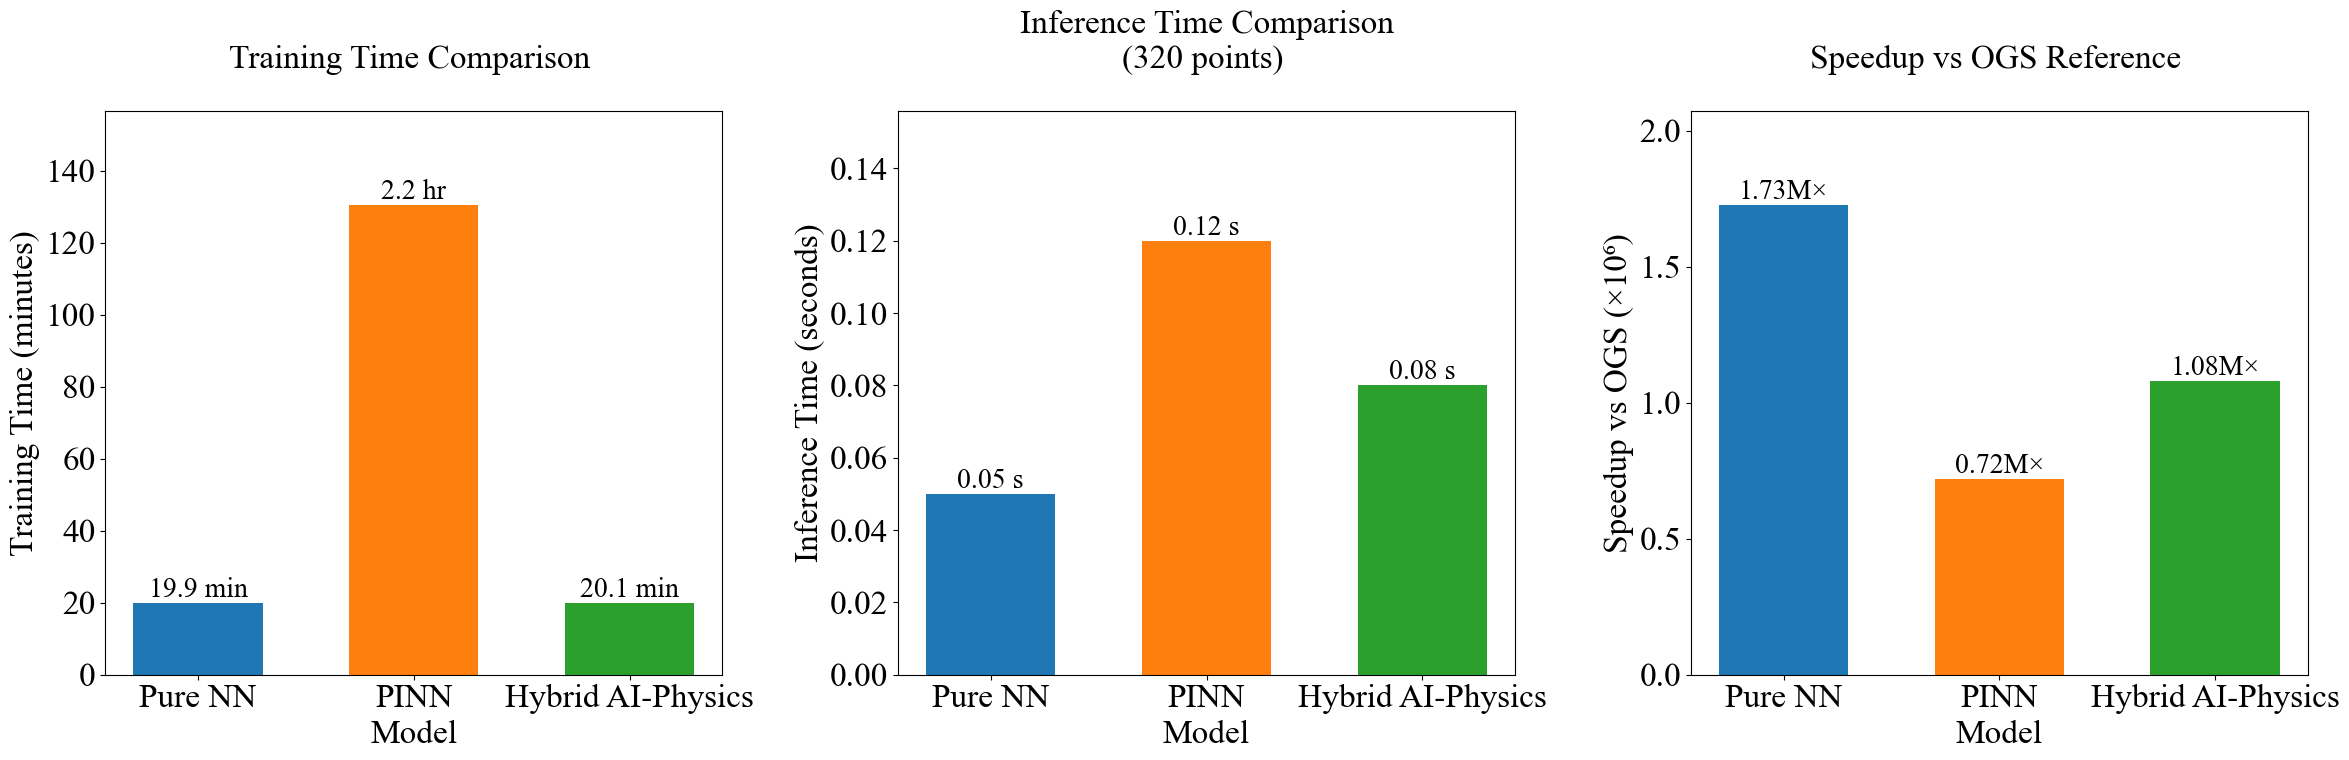

✓ Computational efficiency comparison saved


In [8]:
import matplotlib.pyplot as plt
import numpy as np

def plot_computational_efficiency():
    """Plot computational efficiency comparison for three models"""
    
    # Data for three models (excluding Physics-Only and OGS)
    models = ['Pure NN', 'PINN', 'Hybrid AI-Physics']
    
    # Colors for each model
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
    
    # Training Time (in seconds)
    training_time = [1197, 7838, 1203]  # seconds
    
    # Inference Time (in seconds for 320 points)
    inference_time = [0.05, 0.12, 0.08]  # seconds
    
    # Speedup vs OGS
    speedup = [1728000, 720000, 1080000]  # times faster
    
    # Create figure with 3 subplots
    fig, axes = plt.subplots(1, 3, figsize=(24, 8))
    
    x = np.arange(len(models))
    width = 0.6
    
    # Plot 1: Training Time
    ax1 = axes[0]
    training_time_min = [t/60 for t in training_time]  # Convert to minutes
    bars1 = ax1.bar(x, training_time_min, width, color=colors)
    
    # Add value labels on bars
    for i, bar in enumerate(bars1):
        height = bar.get_height()
        if height < 60:
            label = f'{height:.1f} min'
        else:
            label = f'{height/60:.1f} hr'
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                label,
                ha='center', va='bottom', fontsize=20)
    
    ax1.set_xlabel('Model', fontsize=24)
    ax1.set_ylabel('Training Time (minutes)', fontsize=24)
    ax1.set_title('Training Time Comparison \n', fontsize=24)
    ax1.set_xticks(x)
    ax1.set_xticklabels(models, fontsize=24)
    ax1.tick_params(axis='y', labelsize=24)
    ax1.set_ylim([0, max(training_time_min) * 1.2])
    
    # Plot 2: Inference Time
    ax2 = axes[1]
    bars2 = ax2.bar(x, inference_time, width, color=colors)
    
    # Add value labels on bars
    for bar in bars2:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.2f} s',
                ha='center', va='bottom', fontsize=20)
    
    ax2.set_xlabel('Model', fontsize=24)
    ax2.set_ylabel('Inference Time (seconds)', fontsize=24)
    ax2.set_title('Inference Time Comparison\n(320 points) \n', fontsize=24)
    ax2.set_xticks(x)
    ax2.set_xticklabels(models, fontsize=24)
    ax2.tick_params(axis='y', labelsize=24)
    ax2.set_ylim([0, max(inference_time) * 1.3])
    
    # Plot 3: Speedup vs OGS (log scale)
    ax3 = axes[2]
    speedup_millions = [s/1e6 for s in speedup]  # Convert to millions
    bars3 = ax3.bar(x, speedup_millions, width, color=colors)
    
    # Add value labels on bars
    for i, bar in enumerate(bars3):
        height = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.2f}M×',
                ha='center', va='bottom', fontsize=20)
    
    ax3.set_xlabel('Model', fontsize=24)
    ax3.set_ylabel('Speedup vs OGS (×10⁶)', fontsize=24)
    ax3.set_title('Speedup vs OGS Reference \n', fontsize=24)
    ax3.set_xticks(x)
    ax3.set_xticklabels(models, fontsize=24)
    ax3.tick_params(axis='y', labelsize=24)
    ax3.set_ylim([0, max(speedup_millions) * 1.2])
    
    plt.tight_layout()
    plt.savefig('computational_efficiency_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Computational efficiency comparison saved")

# Call the function
plot_computational_efficiency()


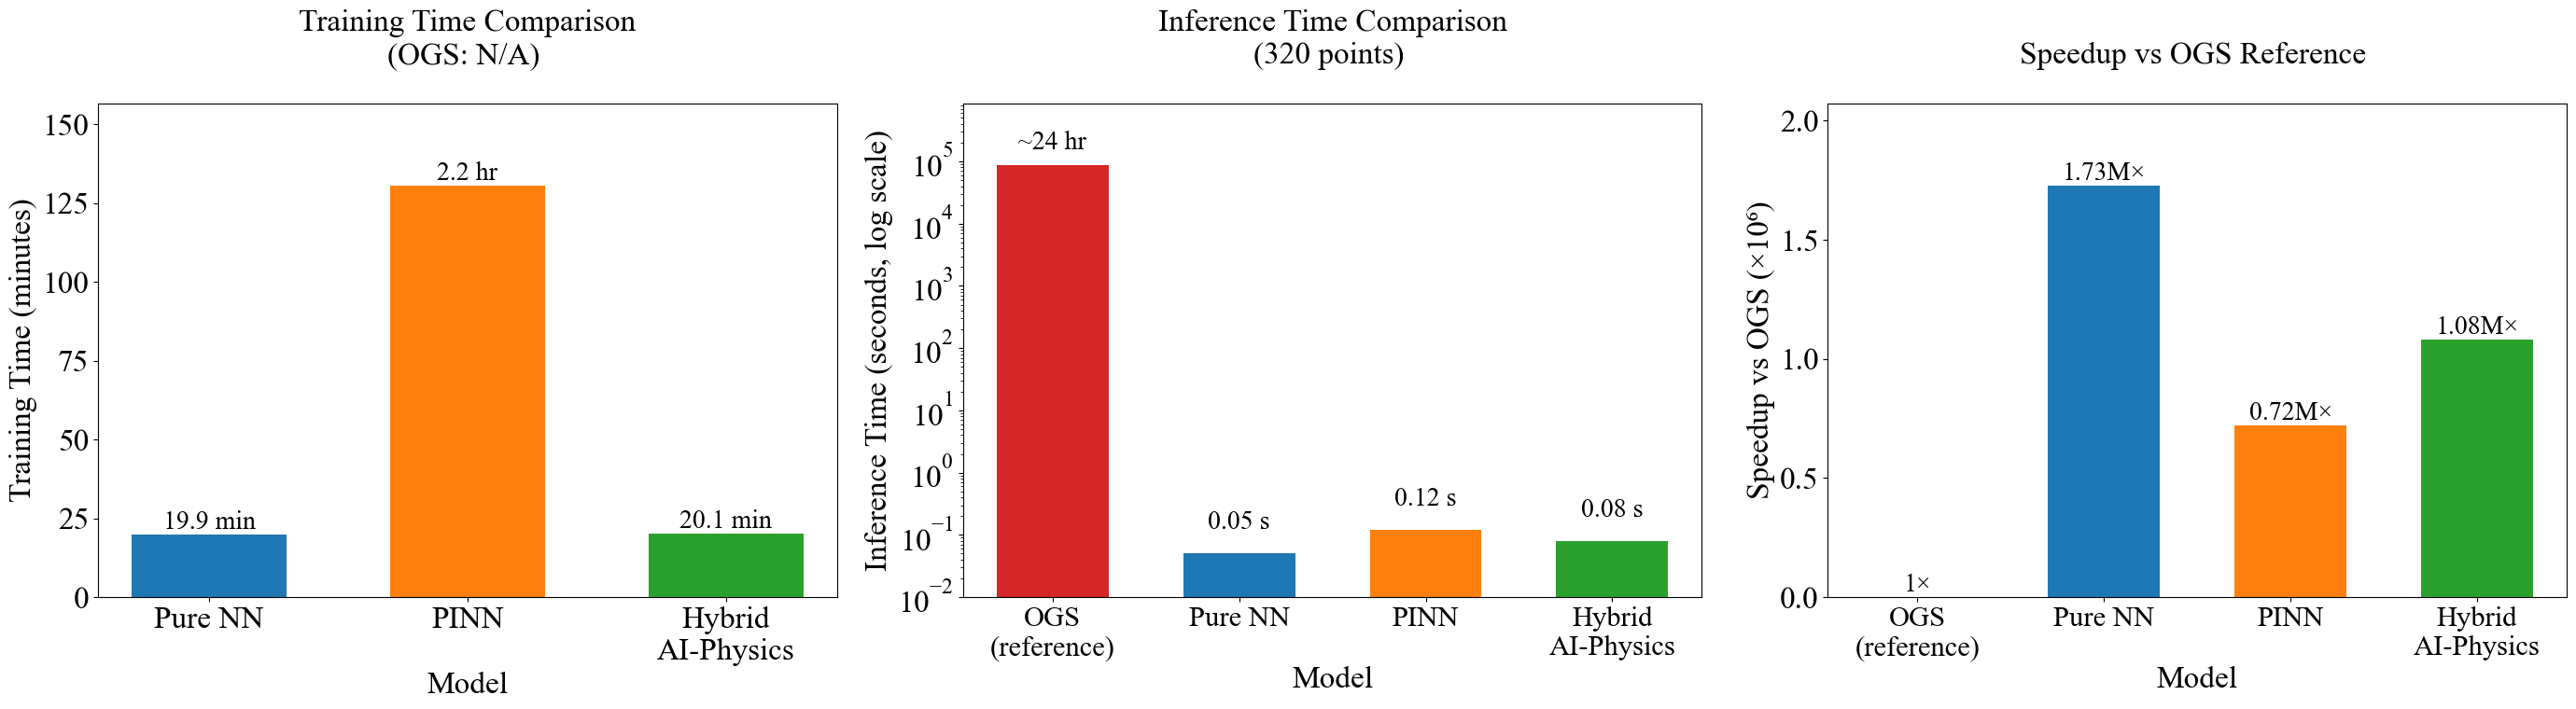

✓ Computational efficiency comparison saved


In [9]:
import matplotlib.pyplot as plt
import numpy as np

def plot_computational_efficiency():
    """Plot computational efficiency comparison for four approaches"""
    
    # Data for four approaches (including OGS reference)
    models = ['OGS\n(reference)', 'Pure NN', 'PINN', 'Hybrid\nAI-Physics']
    
    # Colors for each model
    colors = ['#d62728', '#1f77b4', '#ff7f0e', '#2ca02c']  # Added red for OGS
    
    # Training Time (in seconds) - OGS has N/A, we'll use 0 and handle separately
    training_time = [0, 1197, 7838, 1203]  # seconds
    training_time_available = [False, True, True, True]  # Track which have training time
    
    # Inference Time (in seconds for 320 points)
    inference_time = [24*3600, 0.05, 0.12, 0.08]  # seconds (24 hours = 86400 seconds)
    
    # Speedup vs OGS
    speedup = [1, 1728000, 720000, 1080000]  # times faster
    
    # Create figure with 3 subplots
    fig, axes = plt.subplots(1, 3, figsize=(28, 8))
    
    x = np.arange(len(models))
    width = 0.6
    
    # Plot 1: Training Time (excluding OGS)
    ax1 = axes[0]
    x_train = np.arange(1, len(models))  # Exclude OGS
    training_time_min = [t/60 for t in training_time[1:]]  # Convert to minutes, exclude OGS
    bars1 = ax1.bar(x_train, training_time_min, width, color=colors[1:])
    
    # Add value labels on bars
    for i, bar in enumerate(bars1):
        height = bar.get_height()
        if height < 60:
            label = f'{height:.1f} min'
        else:
            label = f'{height/60:.1f} hr'
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                label,
                ha='center', va='bottom', fontsize=20)
    
    ax1.set_xlabel('Model', fontsize=24)
    ax1.set_ylabel('Training Time (minutes)', fontsize=24)
    ax1.set_title('Training Time Comparison\n(OGS: N/A) \n', fontsize=24)
    ax1.set_xticks(x_train)
    ax1.set_xticklabels(models[1:], fontsize=24)
    ax1.tick_params(axis='y', labelsize=24)
    ax1.set_ylim([0, max(training_time_min) * 1.2])
    
    # Plot 2: Inference Time (log scale to show the huge difference)
    ax2 = axes[1]
    bars2 = ax2.bar(x, inference_time, width, color=colors, log=True)
    
    # Add value labels on bars
    for i, bar in enumerate(bars2):
        height = bar.get_height()
        if i == 0:
            label = f'~24 hr'
            y_pos = height * 1.5
        else:
            label = f'{height:.2f} s'
            y_pos = height * 2
        ax2.text(bar.get_x() + bar.get_width()/2., y_pos,
                label,
                ha='center', va='bottom', fontsize=20)
    
    ax2.set_xlabel('Model', fontsize=24)
    ax2.set_ylabel('Inference Time (seconds, log scale)', fontsize=24)
    ax2.set_title('Inference Time Comparison\n(320 points) \n', fontsize=24)
    ax2.set_xticks(x)
    ax2.set_xticklabels(models, fontsize=22)
    ax2.tick_params(axis='y', labelsize=24)
    ax2.set_ylim([0.01, max(inference_time) * 10])
    
    # Plot 3: Speedup vs OGS (log scale)
    ax3 = axes[2]
    speedup_millions = [s/1e6 for s in speedup]  # Convert to millions
    bars3 = ax3.bar(x, speedup_millions, width, color=colors)
    
    # Add value labels on bars
    for i, bar in enumerate(bars3):
        height = bar.get_height()
        if i == 0:
            label = f'1×'
        else:
            label = f'{height:.2f}M×'
        ax3.text(bar.get_x() + bar.get_width()/2., height,
                label,
                ha='center', va='bottom', fontsize=20)
    
    ax3.set_xlabel('Model', fontsize=24)
    ax3.set_ylabel('Speedup vs OGS (×10⁶)', fontsize=24)
    ax3.set_title('Speedup vs OGS Reference \n', fontsize=24)
    ax3.set_xticks(x)
    ax3.set_xticklabels(models, fontsize=22)
    ax3.tick_params(axis='y', labelsize=24)
    ax3.set_ylim([0, max(speedup_millions) * 1.2])
    
    plt.tight_layout()
    plt.savefig('computational_efficiency_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✓ Computational efficiency comparison saved")

# Call the function
plot_computational_efficiency()
